In [2]:
import pickle
import json
import torch
import pandas as pd
import os

from post_analysis import *

/opt/anaconda3/envs/firegnn/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
def load_pickle(filepath):
    with open(filepath, 'rb') as f:
        obj = pickle.load(f)
    return obj

def load_json(filepath):
    with open(filepath, 'rb') as f:
        obj = json.load(f)
    return obj

# Global Rule Importance

In [8]:
df_kgrule = pd.read_csv("../nesy_gnn/results/explain/AD_KG/ANMerge/4/KGRules.csv", index_col=0)
df_kgrule.set_index(keys='name', inplace=True)
rule_evid_dict=df_kgrule['evidence'].to_dict()

rule_evid_dict

{'chain_SORL1_APP_CTL': 'g(HGNC:"SORL1") → APP → Alzheimer Disease (net sign: -)',
 'chain_MME_APP_CTL': 'p(HGNC:"MME") → APP → Alzheimer Disease (net sign: -)',
 'chain_CTSD_APP_AD': 'g(HGNC:"CTSD",var("C,224,T")) → APP → Alzheimer Disease (net sign: +)',
 'direct_BIN1_AD': 'g(HGNC:"BIN1") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")',
 'direct_PICALM_AD': 'g(HGNC:"PICALM") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")',
 'direct_CD33_AD': 'g(HGNC:"CD33") --rev_increases--> path(MESH:"Alzheimer Disease")',
 'direct_ABCA7_AD': 'g(HGNC:"ABCA7") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")',
 'direct_GAB2_AD': 'g(HGNC:"GAB2") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")',
 'chain_RTN4_APP_CTL': 'g(HGNC:"RTN4") → APP → Alzheimer Disease (net sign: -)',
 'chain_CYLD_Wnt signaling pathwa_AD': 'g(HGNC:"CYLD") → Wnt signaling pathway → Alzheimer Disease (net sign: +)',
 'direct_CCR2_AD': 'p(HGNC:"CCR2") --positive_correlation--> p

In [9]:
df_rules = pd.read_csv("../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/df_rules_importance.csv",
                       index_col=0)
df_rules['evidence'] = df_rules['rule_name'].map(rule_evid_dict)
df_rules

,rule,alpha,theta,mean_activation,std_activation,activation_rate,grad_rule_importance_prediction,importance_class_0,importance_class_1,Permutation_importance(true_label),Permutation_importance(pred_label),Integrated_Gradient_importance(true_label),Integrated_Gradient_importance(pred_label),fold,model,rule_name,dataset,k,backbone,evidence
0,0,1.072732,0.028507,0.478543,0.169947,0.280753,0.033956,0.018344,0.043590,2.362391e-04,0.000009,0.008519,0.008708,1,FuzzyGAT_topo,degrees,ANMerge,4,GAT,NaN
1,1,0.947316,0.012711,0.482814,0.186225,0.356006,0.054627,0.025849,0.070291,5.451671e-04,0.000175,0.018178,0.017757,1,FuzzyGAT_topo,clustering,ANMerge,4,GAT,NaN
2,2,0.968920,-0.010963,0.482680,0.134000,0.179450,0.045100,0.086895,0.027092,-2.634974e-04,0.000028,0.009560,0.009037,1,FuzzyGAT_topo,eigenvector_centrality,ANMerge,4,GAT,NaN
3,3,1.040114,0.025417,0.480132,0.166282,0.280753,0.035440,0.029834,0.042852,-1.181195e-04,0.000037,0.008705,0.008736,1,FuzzyGAT_topo,degree_centrality,ANMerge,4,GAT,NaN
4,4,0.981712,0.008732,0.524371,0.097692,0.885673,0.030418,0.056334,0.010072,5.451671e-05,0.000009,0.002870,0.003210,1,FuzzyGAT_topo,avg_edge_weight,ANMerge,4,GAT,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37335,741,0.993151,-0.009017,0.502472,0.224352,0.493488,0.000857,0.001510,0.001078,-9.086119e-06,0.000000,0.000376,0.000343,5,FuzzyGIN_topo_all_rules,chain_AKAP13_4hops_AD,ANMerge,4,GIN,AKAP13 → MAPT → APP → Alzheimer Disease
37336,742,1.000581,0.002199,0.499538,0.225266,0.492041,0.001951,0.003077,0.001520,-1.110223e-16,0.000000,0.000784,0.000785,5,FuzzyGIN_topo_all_rules,chain_VPS35_5hops_AD,ANMerge,4,GIN,VPS35 → APP → APP → TNF → Alzheimer Disease
37337,743,0.999908,-0.001201,0.500216,0.225140,0.492041,0.002992,0.004801,0.002673,0.000000e+00,0.000000,0.001186,0.001164,5,FuzzyGIN_topo_all_rules,chain_VPS35_5hops_CTL,ANMerge,4,GIN,VPS35 → APP → APP → nitric oxide → Alzheimer D...
37338,744,1.000251,-0.003062,0.500587,0.225201,0.492041,0.004529,0.004010,0.005291,-7.268895e-05,0.000000,0.002017,0.001989,5,FuzzyGIN_topo_all_rules,chain_VPS35_4hops_AD,ANMerge,4,GIN,VPS35 → APP → APP → Alzheimer Disease


In [12]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"

df = df_rules[(df_rules['dataset']==dataset) &
                   (df_rules['k']==k) &
                   (df_rules['model']==model_type)]

df_rule_act = df[['rule_name', 'evidence', 'alpha', 'theta', 'activation_rate']]

df_rule_act = df_rule_act.sort_values(by='activation_rate', ascending=False)
df_rule_act.dropna()

,rule_name,evidence,alpha,theta,activation_rate
223,chain_CCR2_microglial cell acti_AD,"p(HGNC:""CCR2"") → microglial cell activation → ...",1.137148,-0.060320,0.557164
222,chain_CCR2_amyloid-beta_AD,"p(HGNC:""CCR2"") → amyloid-beta → Alzheimer Dise...",1.094857,-0.047571,0.551375
221,chain_CCR2_Microglia_AD,"p(HGNC:""CCR2"") → Microglia → Alzheimer Disease...",1.096097,-0.051757,0.551375
224,chain_CCR2_memory_AD,"p(HGNC:""CCR2"") → memory → Alzheimer Disease (n...",1.109211,-0.034677,0.542692
220,direct_CCR2_AD,"p(HGNC:""CCR2"") --positive_correlation--> path(...",1.129640,-0.031258,0.541245
...,...,...,...,...,...
797,chain_HDAC2_H3F3A_CTL,"p(HGNC:""HDAC2"") → H3F3A → Alzheimer Disease (n...",1.241814,0.104519,0.450072
749,direct_HSPD1_CTL,"p(RGD:""Hspd1"") --negative_correlation--> path(...",1.003769,0.000772,0.447178
379,direct_HSPD1_CTL,"p(RGD:""Hspd1"") --negative_correlation--> path(...",1.056574,0.049272,0.437048
194,direct_HSPD1_CTL,"p(RGD:""Hspd1"") --negative_correlation--> path(...",1.025307,0.033063,0.437048


Top-5 rule_name by grad_rule_importance_prediction:
['chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_APP_AD', 'direct_ITGAM_AD', 'direct_ABCA7_AD', 'chain_HDAC2_memory_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/FuzzyGAT_direct_rules_Global_grad_rule_importance_prediction.png


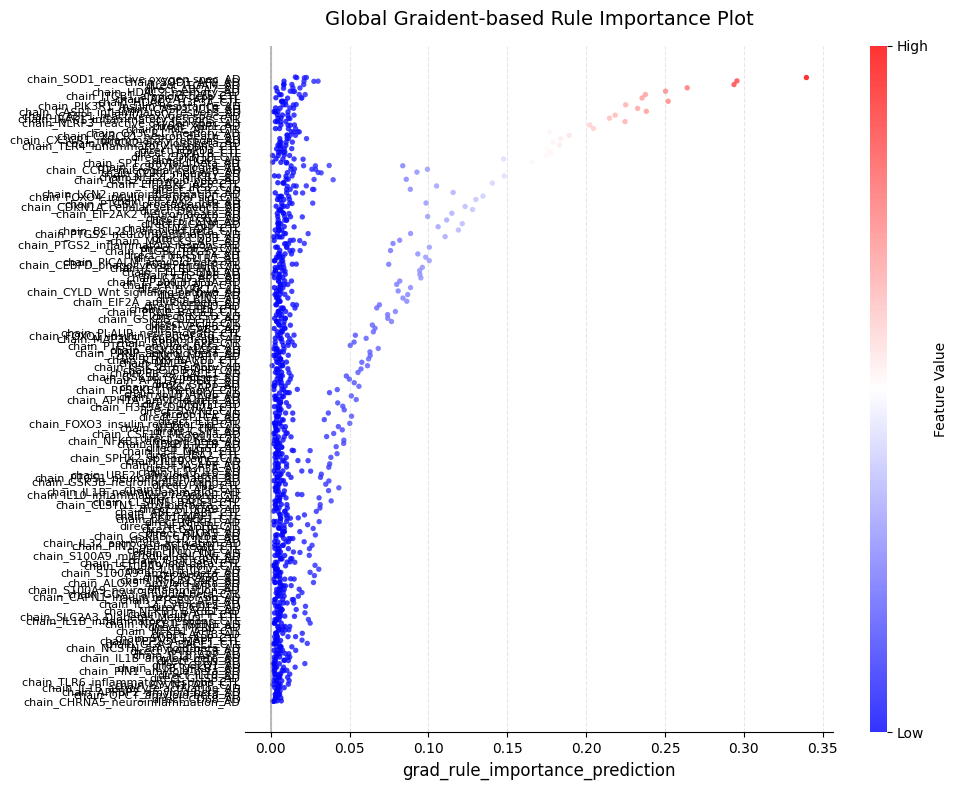

                                    grad_rule_importance_prediction
rule_name                                                          
chain_SOD1_reactive oxygen spec_AD                         0.083116
chain_SOD1_APP_AD                                          0.076500
direct_ITGAM_AD                                            0.068923
direct_ABCA7_AD                                            0.061631
chain_HDAC2_memory_AD                                      0.059204
chain_ITGB1_amyloid-beta_CTL                               0.057898
chain_ABCA7_APP_CTL                                        0.057683
chain_HDAC2_H3F3A_CTL                                      0.056571
chain_PIK3R1_Insulin Resistance_AD                         0.054572
chain_CASP1_IL1B_AD                                        0.053641
Top-5 rule_name by Permutation_importance(pred_label):
['chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_APP_AD', 'chain_HDAC2_memory_AD', 'chain_CASP1_inflammatory respons_AD', 'chai

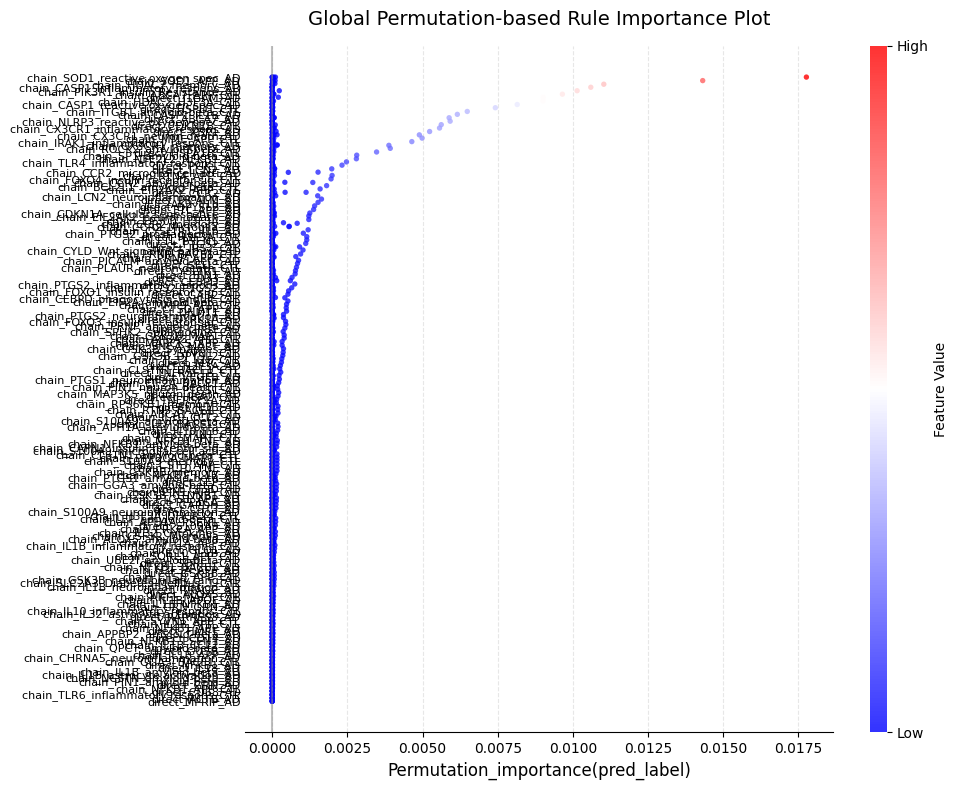

                                     Permutation_importance(pred_label)
rule_name                                                              
chain_SOD1_reactive oxygen spec_AD                             0.003585
chain_SOD1_APP_AD                                              0.002892
chain_HDAC2_memory_AD                                          0.002228
chain_CASP1_inflammatory respons_AD                            0.002119
chain_PIK3R1_Insulin Resistance_AD                             0.002075
chain_ABCA7_APP_CTL                                            0.001949
direct_ITGAM_AD                                                0.001844
chain_HDAC2_H3F3A_CTL                                          0.001809
chain_CASP1_reactive oxygen spec_AD                            0.001632
direct_HSPD1_CTL                                               0.001488
Top-5 rule_name by Integrated_Gradient_importance(pred_label):
['chain_SOD1_reactive oxygen spec_AD', 'direct_ITGAM_AD', 'chain_SOD1_APP

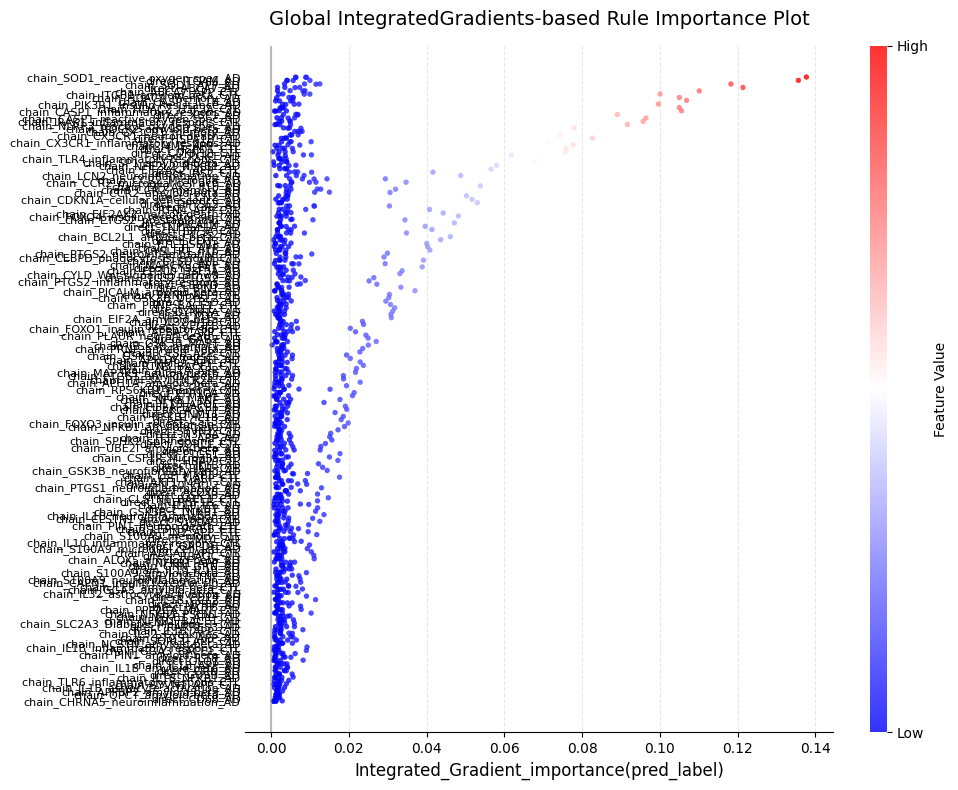

                                    Integrated_Gradient_importance(pred_label)
rule_name                                                                     
chain_SOD1_reactive oxygen spec_AD                                    0.033695
direct_ITGAM_AD                                                       0.031929
chain_SOD1_APP_AD                                                     0.030904
direct_ABCA7_AD                                                       0.028034
chain_ABCA7_APP_CTL                                                   0.026732
chain_ITGB1_amyloid-beta_CTL                                          0.024727
chain_HDAC2_memory_AD                                                 0.024480
chain_CASP1_IL1B_AD                                                   0.024181
chain_PIK3R1_Insulin Resistance_AD                                    0.023911
chain_HDAC2_H3F3A_CTL                                                 0.023250


In [14]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"

plot_df = df_rules[(df_rules['dataset']==dataset) &
                   (df_rules['k']==k) &
                   (df_rules['model']==model_type)]

importance_types = ['grad_rule_importance_prediction',
                                # 'Permutation_importance(true_label)',
                                'Permutation_importance(pred_label)',
                                # 'Integrated_Gradient_importance(true_label)',
                                'Integrated_Gradient_importance(pred_label)']
title_name = ['Graident-based', 'Permutation-based', 'IntegratedGradients-based']

for i, rip in enumerate(importance_types):
    x_col = rip
    y_col = 'rule_name'

    save_dir = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules"
    save_path = os.path.join(save_dir, f'{model_type}_Global_{rip}.png')
    
    df = plot_rule_importance(df=plot_df, 
                                        x_col=x_col, 
                                        y_col=y_col, 
                                        title=f"Global {title_name[i]} Rule Importance Plot",
                                        cmap='bwr',
                                        central_vertical_line=0.0,
                                        interpolate=False,
                                        save_path=save_path,
                                        )
    print(df.head(10))

Top-5 rule_name by grad_rule_importance_prediction:
['chain_TXN_5hops_CTL', 'chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_4hops_CTL', 'chain_SOD1_5hops_AD', 'chain_SOD1_3hops_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/FuzzyGAT_all_rules_Global_grad_rule_importance_prediction.png


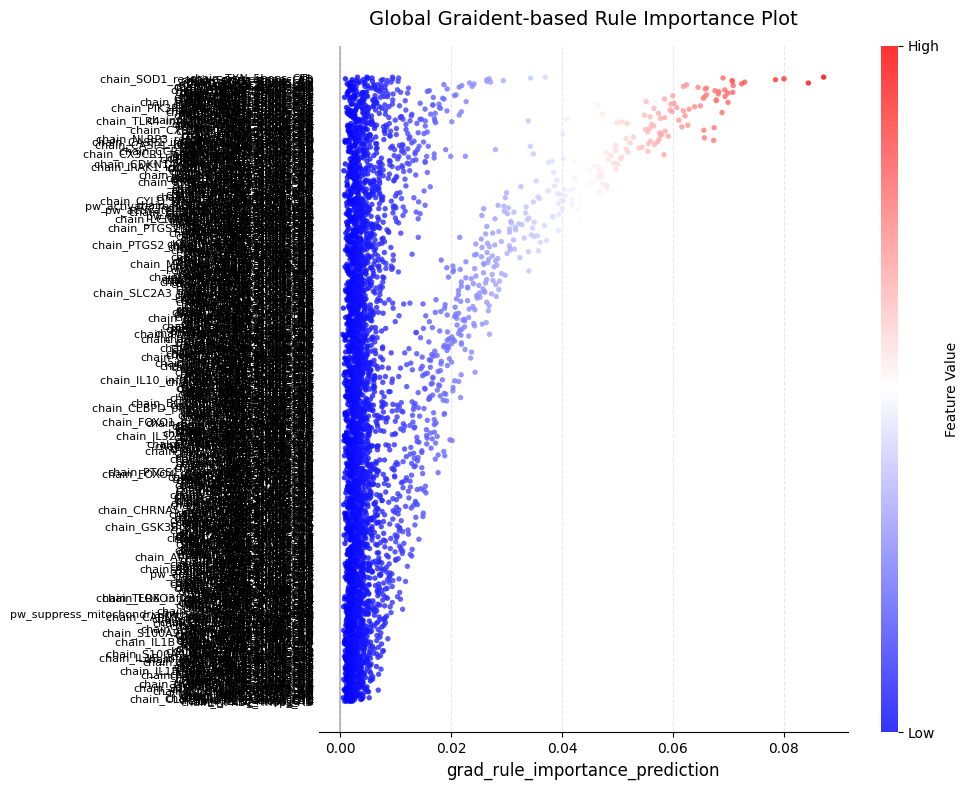

chain_TXN_5hops_CTL :  TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
chain_SOD1_reactive oxygen spec_AD :  p(MGI:"Sod1",var("G, 93, A")) → reactive oxygen species → Alzheimer Disease (net sign: +)
chain_SOD1_4hops_CTL :  SOD1 → APP → nitric oxide → Alzheimer Disease
chain_SOD1_5hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_SOD1_3hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease
chain_SOD1_4hops_AD :  Sod1 → reactive oxygen species → APP → Alzheimer Disease
chain_SOD1_5hops_CTL :  SOD1 → APP → IDE → amyloid-beta → late-onset Alzheimers disease
chain_HDAC2_5hops_AD :  HDAC2 → memory → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_SOD1_APP_AD :  p(HGNC:"SOD1") → APP → Alzheimer Disease (net sign: +)
chain_BCL2_5hops_AD :  BCL2 → CYCS → apoptotic process → neuron death → Alzheimer Disease
chain_HDAC2_3hops_CTL :  HDAC2 → H3F3A → Alzheimer Disease
Top-5 rule_name b

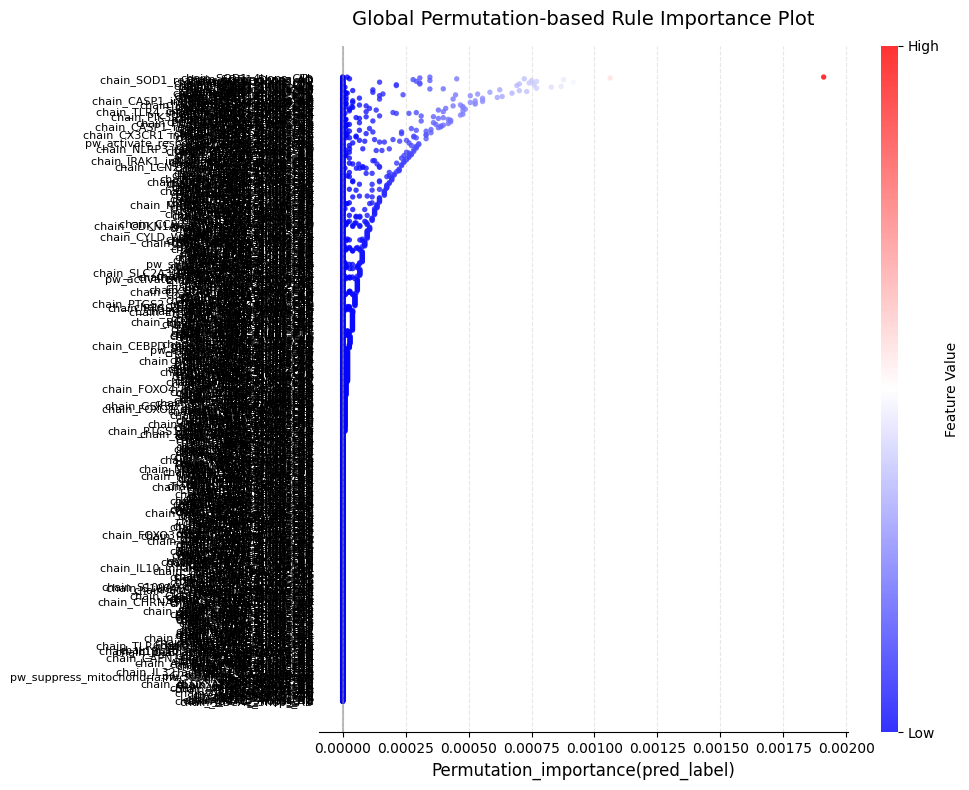

chain_SOD1_4hops_CTL :  SOD1 → APP → nitric oxide → Alzheimer Disease
chain_SOD1_5hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_SOD1_reactive oxygen spec_AD :  p(MGI:"Sod1",var("G, 93, A")) → reactive oxygen species → Alzheimer Disease (net sign: +)
chain_SOD1_APP_AD :  p(HGNC:"SOD1") → APP → Alzheimer Disease (net sign: +)
chain_SOD1_3hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease
chain_TXN_5hops_CTL :  TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
chain_HDAC2_3hops_CTL :  HDAC2 → H3F3A → Alzheimer Disease
chain_SOD1_5hops_CTL :  SOD1 → APP → IDE → amyloid-beta → late-onset Alzheimers disease
chain_BCL2_5hops_CTL :  BCL2 → apoptotic process → neuron death → noradrenaline → Alzheimer Disease
chain_HDAC2_5hops_AD :  HDAC2 → memory → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_PIK3R1_5hops_CTL :  PIK3R1 → Insulin Resistance → amyloid-beta → nitric oxide → A

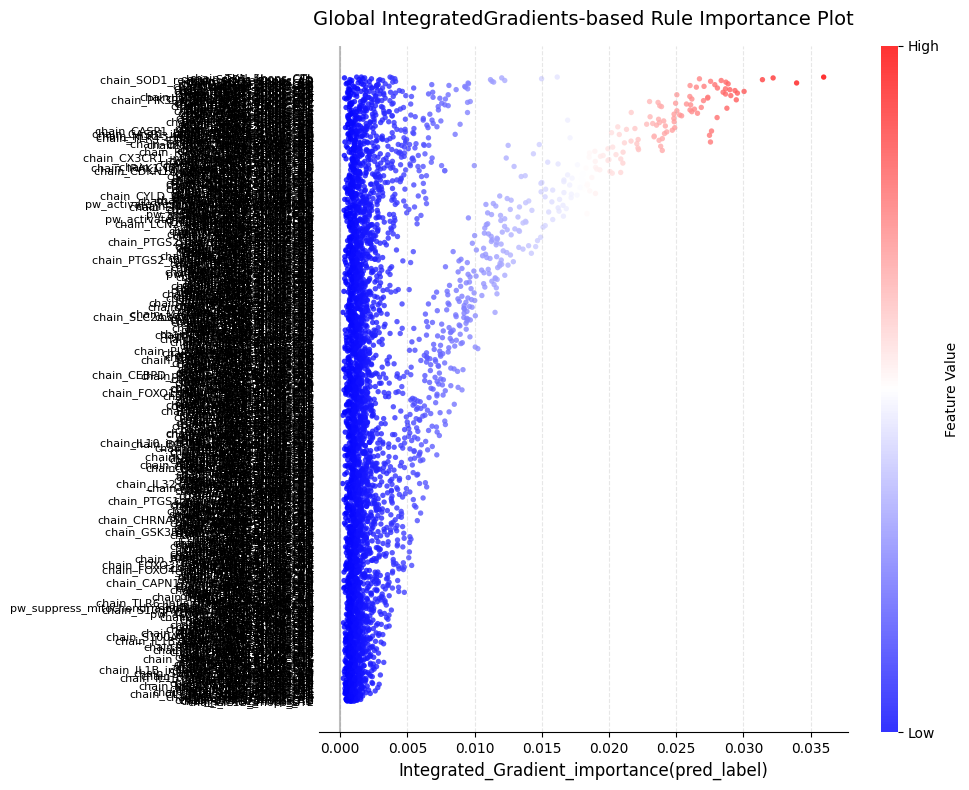

chain_TXN_5hops_CTL :  TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
chain_SOD1_4hops_CTL :  SOD1 → APP → nitric oxide → Alzheimer Disease
chain_SOD1_reactive oxygen spec_AD :  p(MGI:"Sod1",var("G, 93, A")) → reactive oxygen species → Alzheimer Disease (net sign: +)
chain_SOD1_5hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_SOD1_3hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease
chain_SOD1_4hops_AD :  Sod1 → reactive oxygen species → APP → Alzheimer Disease
chain_SOD1_5hops_CTL :  SOD1 → APP → IDE → amyloid-beta → late-onset Alzheimers disease
chain_HDAC2_5hops_AD :  HDAC2 → memory → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_SOD1_APP_AD :  p(HGNC:"SOD1") → APP → Alzheimer Disease (net sign: +)
chain_NEDD8_5hops_CTL :  NEDD8 → neuron apoptotic process → regulation of synaptic activity → APP → Alzheimer Disease
chain_BCL2_5hops_AD :  BCL2 → CYCS → apoptotic p

In [21]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_all_rules"

plot_df = df_rules[(df_rules['dataset']==dataset) &
                   (df_rules['k']==k) &
                   (df_rules['model']==model_type)]

importance_types = ['grad_rule_importance_prediction',
                                # 'Permutation_importance(true_label)',
                                'Permutation_importance(pred_label)',
                                # 'Integrated_Gradient_importance(true_label)',
                                'Integrated_Gradient_importance(pred_label)']
title_name = ['Graident-based', 'Permutation-based', 'IntegratedGradients-based']

for i, rip in enumerate(importance_types):
    x_col = rip
    y_col = 'rule_name'

    save_dir = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules"
    save_path = os.path.join(save_dir, f'{model_type}_Global_{rip}.png')
    
    df = plot_rule_importance(df=plot_df, 
                                        x_col=x_col, 
                                        y_col=y_col, 
                                        title=f"Global {title_name[i]} Rule Importance Plot",
                                        cmap='bwr',
                                        central_vertical_line=0.0,
                                        interpolate=False,
                                        save_path=save_path,
                                        )
    if 'rule_name' not in df.columns and df.index.name == 'rule_name':
        df = df.reset_index()
    df['evidence'] = df['rule_name'].map(rule_evid_dict)
    for j, row in df.iterrows():
        print(row['rule_name'],': ', row['evidence'])
        if j > 9:
            break

Top-5 rule_name by grad_rule_importance_prediction:
['chain_TXN_5hops_CTL', 'chain_SOD1_5hops_AD', 'chain_SOD1_3hops_AD', 'chain_SOD1_5hops_CTL', 'chain_SOD1_4hops_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/FuzzyGAT_topo_all_rules_Global_grad_rule_importance_prediction.png


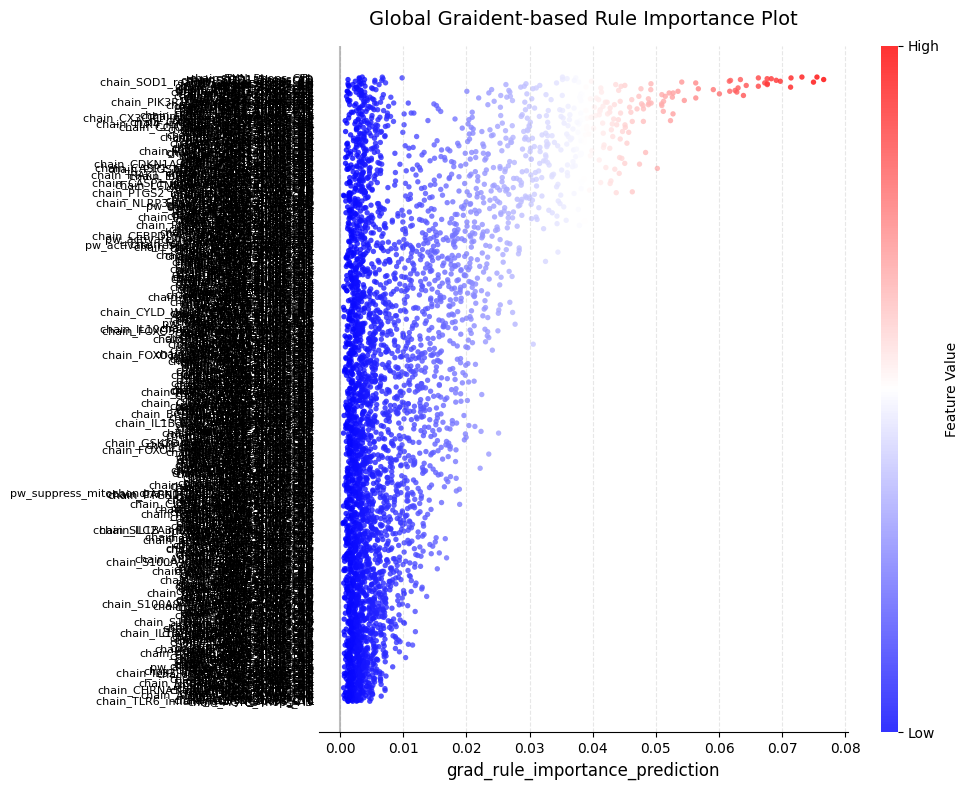

chain_TXN_5hops_CTL :  TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
chain_SOD1_5hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_SOD1_3hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease
chain_SOD1_5hops_CTL :  SOD1 → APP → IDE → amyloid-beta → late-onset Alzheimers disease
chain_SOD1_4hops_CTL :  SOD1 → APP → nitric oxide → Alzheimer Disease
chain_SOD1_reactive oxygen spec_AD :  p(MGI:"Sod1",var("G, 93, A")) → reactive oxygen species → Alzheimer Disease (net sign: +)
chain_SOD1_4hops_AD :  Sod1 → reactive oxygen species → APP → Alzheimer Disease
chain_SOD1_APP_AD :  p(HGNC:"SOD1") → APP → Alzheimer Disease (net sign: +)
direct_ABCA7_AD :  g(HGNC:"ABCA7") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")
chain_ABCA7_3hops_CTL :  ABCA7 → APP → Alzheimer Disease
chain_ABCA7_4hops_AD :  ABCA7 → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
Top-5 rule_name by Per

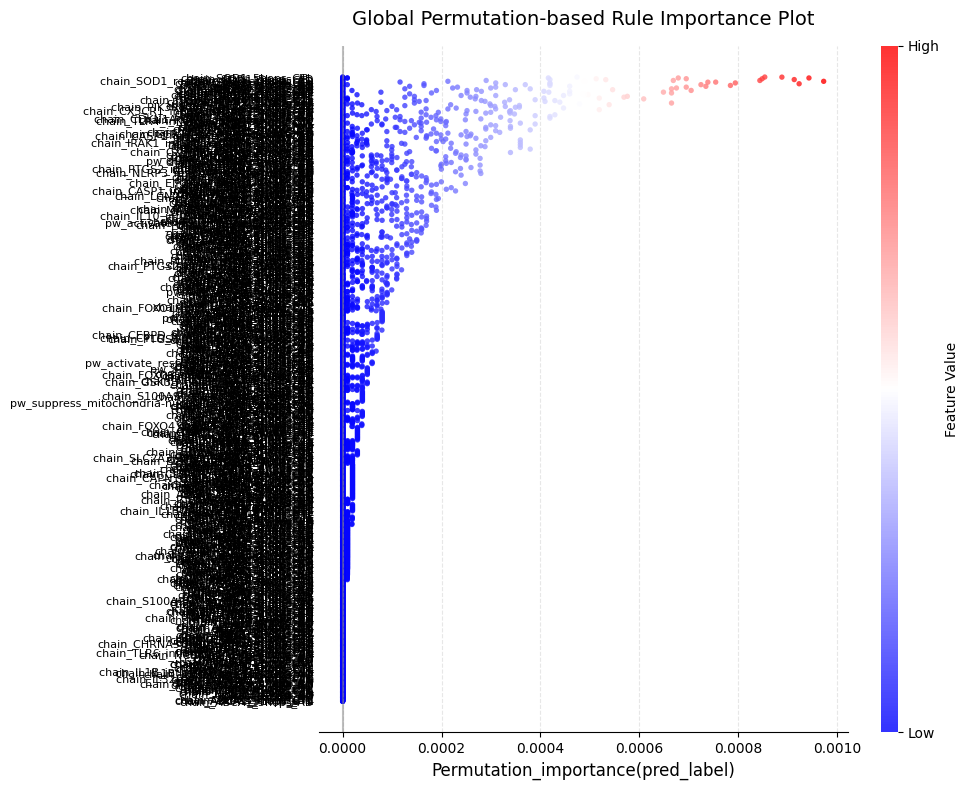

chain_SOD1_5hops_CTL :  SOD1 → APP → IDE → amyloid-beta → late-onset Alzheimers disease
chain_SOD1_5hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_TXN_5hops_CTL :  TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
chain_SOD1_3hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease
chain_SOD1_reactive oxygen spec_AD :  p(MGI:"Sod1",var("G, 93, A")) → reactive oxygen species → Alzheimer Disease (net sign: +)
chain_SOD1_4hops_CTL :  SOD1 → APP → nitric oxide → Alzheimer Disease
chain_ABCA7_4hops_CTL :  ABCA7 → cholesterol efflux → APP → Alzheimer Disease
chain_SOD1_4hops_AD :  Sod1 → reactive oxygen species → APP → Alzheimer Disease
chain_ABCA7_4hops_AD :  ABCA7 → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_SOD1_APP_AD :  p(HGNC:"SOD1") → APP → Alzheimer Disease (net sign: +)
chain_ABCA7_APP_CTL :  p(HGNC:"ABCA7") → APP → Alzheimer Disease (net sign: -)
Top-5 rule_name by

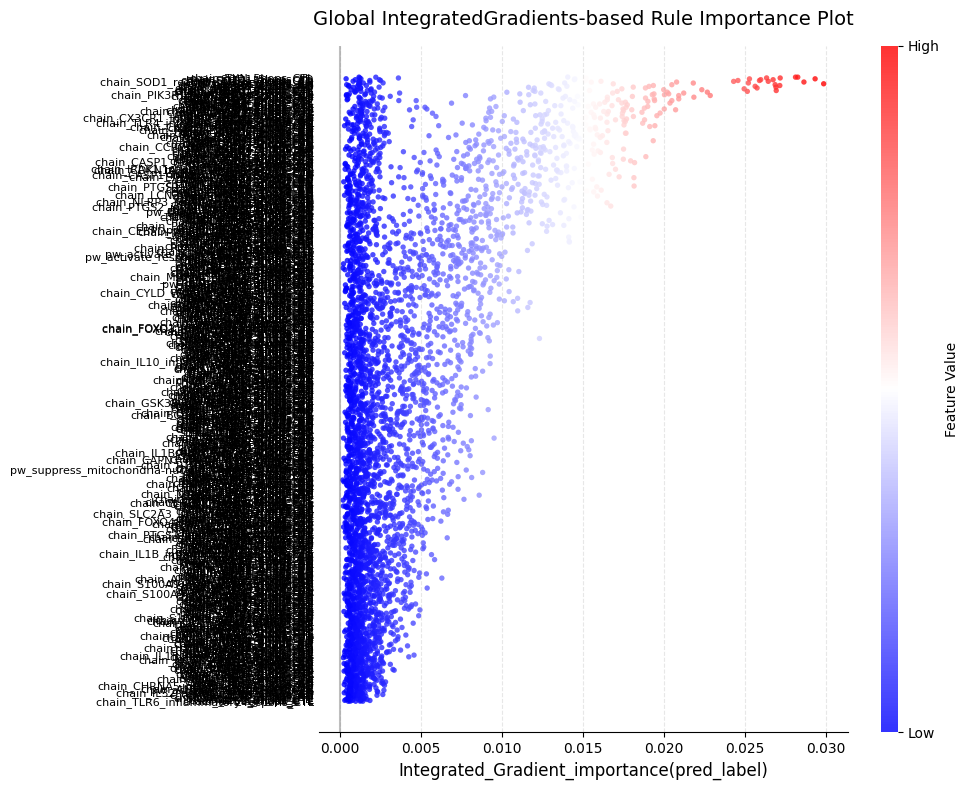

chain_TXN_5hops_CTL :  TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
chain_SOD1_5hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
chain_SOD1_5hops_CTL :  SOD1 → APP → IDE → amyloid-beta → late-onset Alzheimers disease
chain_SOD1_3hops_AD :  Sod1 → reactive oxygen species → Alzheimer Disease
chain_SOD1_4hops_CTL :  SOD1 → APP → nitric oxide → Alzheimer Disease
chain_SOD1_reactive oxygen spec_AD :  p(MGI:"Sod1",var("G, 93, A")) → reactive oxygen species → Alzheimer Disease (net sign: +)
chain_SOD1_4hops_AD :  Sod1 → reactive oxygen species → APP → Alzheimer Disease
chain_SOD1_APP_AD :  p(HGNC:"SOD1") → APP → Alzheimer Disease (net sign: +)
chain_PIK3R1_4hops_AD :  PIK3R1 → Insulin Resistance → amyloid-beta → Alzheimer Disease
direct_ABCA7_AD :  g(HGNC:"ABCA7") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")
chain_PIK3R1_3hops_AD :  PIK3R1 → Insulin Resistance → Alzheimer Disease


In [22]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_topo_all_rules"

plot_df = df_rules[(df_rules['dataset']==dataset) &
                   (df_rules['k']==k) &
                   (df_rules['model']==model_type)]

importance_types = ['grad_rule_importance_prediction',
                                # 'Permutation_importance(true_label)',
                                'Permutation_importance(pred_label)',
                                # 'Integrated_Gradient_importance(true_label)',
                                'Integrated_Gradient_importance(pred_label)']
title_name = ['Graident-based', 'Permutation-based', 'IntegratedGradients-based']

for i, rip in enumerate(importance_types):
    x_col = rip
    y_col = 'rule_name'

    save_dir = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules"
    save_path = os.path.join(save_dir, f'{model_type}_Global_{rip}.png')
    
    df = plot_rule_importance(df=plot_df, 
                                        x_col=x_col, 
                                        y_col=y_col, 
                                        title=f"Global {title_name[i]} Rule Importance Plot",
                                        cmap='bwr',
                                        central_vertical_line=0.0,
                                        interpolate=False,
                                        save_path=save_path,
                                        )
    if 'rule_name' not in df.columns and df.index.name == 'rule_name':
        df = df.reset_index()
    df['evidence'] = df['rule_name'].map(rule_evid_dict)
    for j, row in df.iterrows():
        print(row['rule_name'],': ', row['evidence'])
        if j > 9:
            break

# Prediction Correctness Stratification

In [3]:
def plot_wrong_correct_mean_rulescore(df_samples, 
                                        dataset, 
                                        model_type, 
                                        k,
                                        rule_value_name:str='mean_attribution_score',
                                        plot_correct=True,
                                        cmap='magma',
                                        save_dir=None,
                                        xlim=None,
                                        x_interval=None):

    # calculate mean attribution for wrongly & correctly predicted groups samples
    df_correct = df_samples[df_samples['Label']==df_samples['Prediction']]
    df_wrong = df_samples[df_samples['Label']!=df_samples['Prediction']]

    # Define the columns to group by
    group_cols = ['dataset', 'k', 'model', 'fold']

    # Identify the rule columns (everything from 'degrees' to the end)
    start_idx = df_correct.columns.get_loc('degrees')
    rule_cols = df_correct.columns[start_idx:].tolist()

    # Calculate the mean for the correct predictions
    df_correct_means = df_correct.groupby(group_cols)[rule_cols].mean().reset_index()
    # Calculate the mean for the wrong predictions
    df_wrong_means = df_wrong.groupby(group_cols)[rule_cols].mean().reset_index()

    # Convert from wide to long format
    if plot_correct:
        df_long = df_correct_means.melt(
            id_vars=['dataset', 'k', 'model', 'fold'], # Columns to keep as identifiers
            value_vars=rule_cols,                      # The rule columns to unpivot
            var_name='rule_name',                      # New column containing the rule names
            value_name=rule_value_name        # New column containing the values
        )
        title = f'True Prediction'
    else:
        df_long = df_wrong_means.melt(
            id_vars=['dataset', 'k', 'model', 'fold'], # Columns to keep as identifiers
            value_vars=rule_cols,                      # The rule columns to unpivot
            var_name='rule_name',                      # New column containing the rule names
            value_name=rule_value_name        # New column containing the values
        )
        title = f'False Prediction'

    x_col=rule_value_name
    y_col='rule_name'

    plot_df = df_long[
        (df_long['dataset']==dataset) &
        (df_long['k']==k) &
        (df_long['model']==model_type)
    ].copy()

    plot_df = plot_df.dropna(axis=0)

    mean_importance = plot_df.groupby(y_col)[[x_col]].mean()
    df_rule_order = mean_importance.sort_values(by=x_col, ascending=False)
    
    # save rule order and plot
    save_path = None
    if save_dir is not None:
        save_path = os.path.join(save_dir, f"{dataset}_{model_type}_{title}.png")
        save_rule = os.path.join(save_dir, f"Ordered_rules_{dataset}_{model_type}_{title}.csv")
        df_rule_order.to_csv(save_rule)
    

    df_plot = plot_rule_importance(df=plot_df,
                            x_col=x_col,
                            y_col=y_col,
                            title=title,
                            interpolate=False,
                            cmap=cmap,
                            save_path = save_path,
                            xlim=xlim,
                            x_interval=x_interval)
    return df_rule_order

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/3855376912.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_correct_means = df_correct.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/3855376912.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_wrong_means = df_wrong.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['chain_TXN_5hops_CTL', 'chain_ABCA7_5hops_CTL', 'chain_ABCA7_4hops_CTL', 'direct_ABCA7_AD', 'chain_ABCA7_3hops_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_topo_all_rules_True Prediction.png


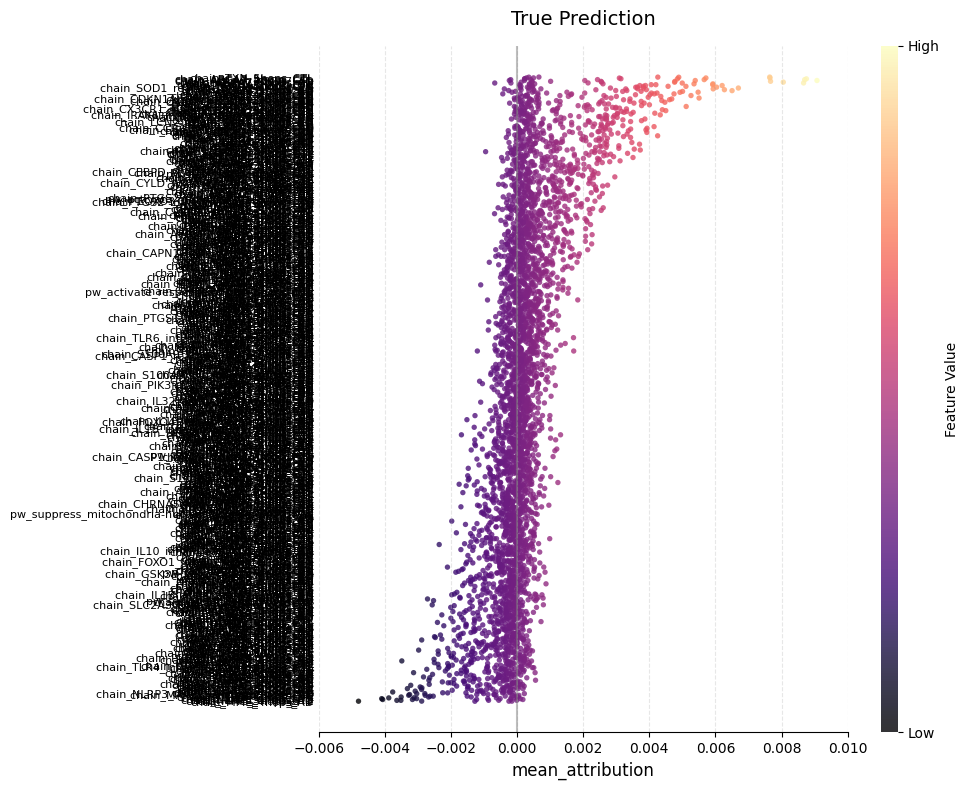

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/3855376912.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_correct_means = df_correct.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/3855376912.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_wrong_means = df_wrong.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['chain_TXN_5hops_CTL', 'chain_SOD1_5hops_CTL', 'chain_ABCA7_APP_CTL', 'chain_SOD1_4hops_CTL', 'chain_SOD1_4hops_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_topo_all_rules_False Prediction.png


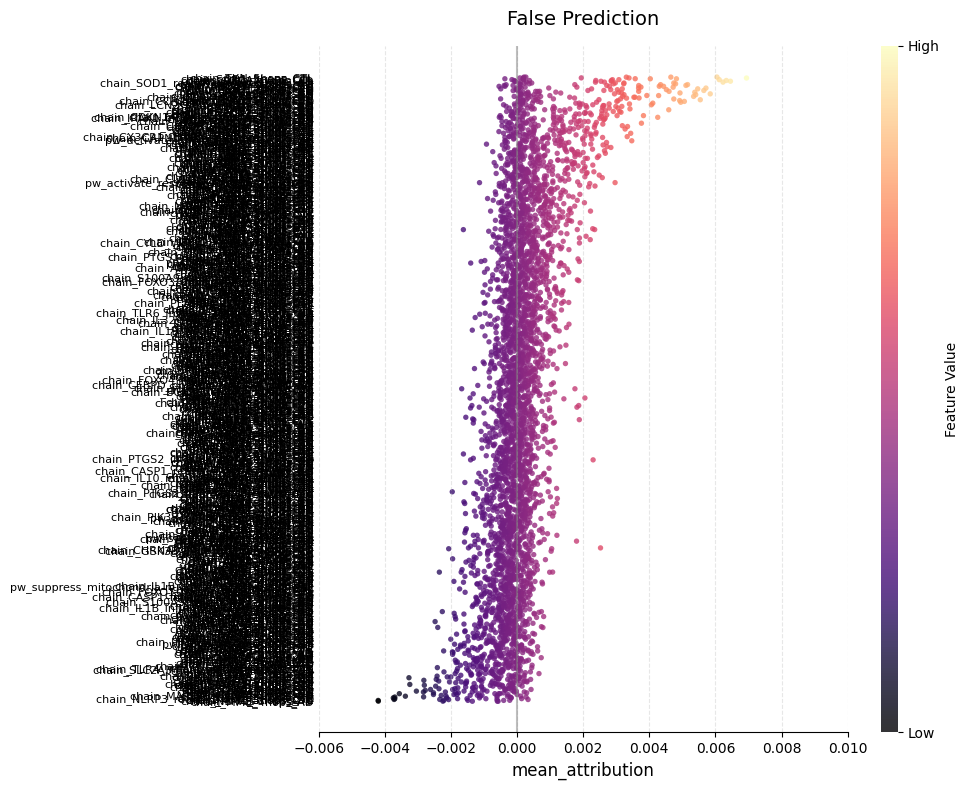

In [42]:
df_attributions = pd.read_csv("../nesy_gnn/results/explain/AD_KG/rules/df_samplewise_rule_attributions.csv")

backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_topo_all_rules"
rule_value_name = 'mean_attribution'

df_gat_all_correct = plot_wrong_correct_mean_rulescore(df_samples=df_attributions, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name=rule_value_name,
                                        plot_correct=True,
                                        cmap='magma',
                                        xlim=(-0.006,0.01),
                                        x_interval=0.002,
                                        save_dir='../nesy_gnn/results/explain/AD_KG/rules'
                                        )

df_gat_all_wrong = plot_wrong_correct_mean_rulescore(df_samples=df_attributions, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name=rule_value_name,
                                        plot_correct=False,
                                        cmap='magma',
                                        xlim=(-0.006,0.01),
                                        x_interval=0.002,
                                        save_dir='../nesy_gnn/results/explain/AD_KG/rules'
                                        )

In [7]:
df_rules = pd.read_csv("../nesy_gnn/results/explain/AD_KG/ANMerge/4/KGRules.csv", index_col=0)
df_rules = df_rules.rename(columns={'name':'rule_name'})

df_gat_all_correct = df_gat_all_correct.reset_index()
df_gat_all_correct = df_gat_all_correct.merge(df_rules, on='rule_name', how='left')

df_gat_all_wrong = df_gat_all_wrong.reset_index()
df_gat_all_wrong = df_gat_all_wrong.merge(df_rules, on='rule_name', how='left')

In [8]:
for i, row in df_gat_all_correct.iterrows():
    print(row['evidence'])
    if i >=10:
        print()
        break

for i, row in df_gat_all_wrong.iterrows():
    print(row['evidence'])
    if i >=10:
        break


TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
ABCA7 → Alzheimer Disease → MMP2 → amyloid-beta → late-onset Alzheimers disease
ABCA7 → cholesterol efflux → APP → Alzheimer Disease
g(HGNC:"ABCA7") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")
ABCA7 → APP → Alzheimer Disease
ABCA7 → Alzheimer Disease → APOE → amyloid-beta → late-onset Alzheimers disease
ABCA7 → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
p(HGNC:"ABCA7") → APP → Alzheimer Disease (net sign: -)
ITGAM → Alzheimer Disease → MMP2 → amyloid-beta → late-onset Alzheimers disease
SOD1 → APP → IDE → amyloid-beta → late-onset Alzheimers disease
SOD1 → APP → nitric oxide → Alzheimer Disease

TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
SOD1 → APP → IDE → amyloid-beta → late-onset Alzheimers disease
p(HGNC:"ABCA7") → APP → Alzheimer Disease (net sign: -)
SOD1 → APP → nitric oxide → Alzheimer Disease
Sod1 → reactive oxygen species → APP → Alzheimer Disease

In [11]:
df_gat_all_correct

,rule_name,mean_attribution,type,conclusion,n_genes,genes,bp,confidence,evidence
0,chain_TXN_5hops_CTL,0.003561,causal_chain,CTL,1.0,TXN,NaN,0.45,TXN → MAP3K5 → apoptotic process → neuron deat...
1,chain_ABCA7_5hops_CTL,0.003448,causal_chain,CTL,1.0,ABCA7,NaN,0.45,ABCA7 → Alzheimer Disease → MMP2 → amyloid-bet...
2,chain_ABCA7_4hops_CTL,0.003440,causal_chain,CTL,1.0,ABCA7,NaN,0.60,ABCA7 → cholesterol efflux → APP → Alzheimer D...
3,direct_ABCA7_AD,0.003403,direct_gene_ad,AD,1.0,ABCA7,NaN,1.00,"g(HGNC:""ABCA7"") --rev_positive_correlation--> ..."
4,chain_ABCA7_3hops_CTL,0.003300,causal_chain,CTL,1.0,ABCA7,NaN,0.75,ABCA7 → APP → Alzheimer Disease
...,...,...,...,...,...,...,...,...,...
741,chain_MME_5hops_CTL,-0.001568,causal_chain,CTL,1.0,MME,NaN,0.45,MME → APP → MMP2 → amyloid-beta → late-onset A...
742,chain_MME_5hops_AD,-0.001684,causal_chain,AD,1.0,MME,NaN,0.45,MME → APP → IDE → amyloid-beta → late-onset Al...
743,chain_NLRP3_4hops_AD,-0.001691,causal_chain,AD,1.0,NLRP3,NaN,0.60,NLRP3 → reactive oxygen species → APP → Alzhei...
744,chain_MME_3hops_CTL,-0.001714,causal_chain,CTL,1.0,MME,NaN,0.75,MME → APP → Alzheimer Disease


### Model = FuzzyGAT_to_all_rules
+ k=4
+ correct_disease_rules top10 
+ their rank in: correct_control_rules; wrong_disease_rules; wrong_control_rules

In [17]:
def get_correct_disease_rules(df_samples, 
                              df_rules, 
                              dataset, 
                              k, 
                              model_type, 
                              rule_value_name, 
                              plot_correct=True, 
                              plot_disease=True):
    # calculate mean attribution for wrongly & correctly predicted groups samples
    if plot_correct:
        df = df_samples[df_samples['Label']==df_samples['Prediction']]
    else:
        df = df_samples[df_samples['Label']!=df_samples['Prediction']]


    df1 = df[df['Prediction']==1]
    df0 = df[df['Prediction']==0]

    # Define the columns to group by
    group_cols = ['dataset', 'k', 'model', 'fold']

    # Identify the rule columns (everything from 'degrees' to the end)
    start_idx = df.columns.get_loc('degrees')
    rule_cols = df.columns[start_idx:].tolist()

    # Calculate the mean for the disease group
    df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
    # Calculate the mean for the control group
    df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()

    # Convert from wide to long format
    if plot_disease:
        df_long = df1_means.melt(
            id_vars=['dataset', 'k', 'model', 'fold'], # Columns to keep as identifiers
            value_vars=rule_cols,                      # The rule columns to unpivot
            var_name='rule_name',                      # New column containing the rule names
            value_name=rule_value_name,        # New column containing the values
        )
    else:
        df_long = df0_means.melt(
            id_vars=['dataset', 'k', 'model', 'fold'], # Columns to keep as identifiers
            value_vars=rule_cols,                      # The rule columns to unpivot
            var_name='rule_name',                      # New column containing the rule names
            value_name=rule_value_name,        # New column containing the values
        )

    plot_df = df_long[
        (df_long['dataset']==dataset) &
        (df_long['k']==k) &
        (df_long['model']==model_type)
    ].copy()

    plot_df = plot_df.dropna(axis=0)
    x_col=rule_value_name
    y_col='rule_name'

    # Sort rules by their mean importance so the most important is at the top
    # Double brackets [[x_col]] and by=x_col safely prevents DataFrame sorting errors
    mean_importance = plot_df.groupby(y_col)[[x_col]].mean()
    order = mean_importance.sort_values(by=x_col, ascending=False).index
    df_ordered_rule = mean_importance.sort_values(by=x_col, ascending=False)

    df_rules = df_rules.rename(columns={'name':'rule_name'})

    df_ordered_rule = df_ordered_rule.reset_index()
    df_correct_disease = df_ordered_rule.merge(df_rules, on='rule_name', how='left')
    return df_correct_disease

In [35]:
df_attributions = pd.read_csv("../nesy_gnn/results/explain/AD_KG/rules/df_samplewise_rule_attributions.csv")
df_rules = pd.read_csv("../nesy_gnn/results/explain/AD_KG/ANMerge/4/KGRules.csv", index_col=0)

backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_topo_all_rules"
rule_value_name = 'mean_attribution'
plot_correct = True
plot_disease = True

df_correct_disease = get_correct_disease_rules(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=True)
df_correct_control = get_correct_disease_rules(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=False)
df_wrong_disease = get_correct_disease_rules(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=True)
df_wrong_control = get_correct_disease_rules(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=False)

dfs = [df_correct_control, df_wrong_disease, df_wrong_control]
df_names = ['TN', 
            'FP', 'FN']

df_rank_comparison = df_correct_disease[['rule_name','evidence']].copy()
df_rank_comparison['RankIn_TP'] = range(1, len(df_rank_comparison)+1)

for i, df in enumerate(dfs):
    if 'rank' not in df.columns:
        df['rank'] = range(1, len(df)+1)
    temp_df = df[['rule_name','rank']].rename(columns={'rank':f'RankIn_{df_names[i]}'})

    df_rank_comparison = df_rank_comparison.merge(temp_df, on='rule_name', how='left')
    
df_rank_comparison.head(10)

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_1140/92054987.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_1140/92054987.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_1140/92054987.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usual

,rule_name,evidence,RankIn_TP,RankIn_TN,RankIn_FP,RankIn_FN
0,chain_ABCA7_4hops_CTL,ABCA7 → cholesterol efflux → APP → Alzheimer D...,1,24,689,5
1,chain_ABCA7_5hops_CTL,ABCA7 → Alzheimer Disease → MMP2 → amyloid-bet...,2,18,686,6
2,direct_ABCA7_AD,"g(HGNC:""ABCA7"") --rev_positive_correlation--> ...",3,16,720,4
3,chain_ABCA7_5hops_AD,ABCA7 → Alzheimer Disease → APOE → amyloid-bet...,4,25,644,8
4,chain_ABCA7_3hops_CTL,ABCA7 → APP → Alzheimer Disease,5,20,715,3
5,chain_ABCA7_4hops_AD,ABCA7 → Alzheimer Disease → homocysteine → lat...,6,10,730,1
6,chain_ABCA7_APP_CTL,"p(HGNC:""ABCA7"") → APP → Alzheimer Disease (net...",7,14,682,2
7,chain_ITGAM_5hops_CTL,ITGAM → Alzheimer Disease → MMP2 → amyloid-bet...,8,11,674,9
8,chain_ITGAM_4hops_AD,ITGAM → Alzheimer Disease → homocysteine → lat...,9,30,680,16
9,chain_TXN_5hops_CTL,TXN → MAP3K5 → apoptotic process → neuron deat...,10,3,5,393


In [36]:
for i, row in df_rank_comparison.iterrows():

    print(row['evidence'])

    if i > 9:
        break

ABCA7 → cholesterol efflux → APP → Alzheimer Disease
ABCA7 → Alzheimer Disease → MMP2 → amyloid-beta → late-onset Alzheimers disease
g(HGNC:"ABCA7") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")
ABCA7 → Alzheimer Disease → APOE → amyloid-beta → late-onset Alzheimers disease
ABCA7 → APP → Alzheimer Disease
ABCA7 → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
p(HGNC:"ABCA7") → APP → Alzheimer Disease (net sign: -)
ITGAM → Alzheimer Disease → MMP2 → amyloid-beta → late-onset Alzheimers disease
ITGAM → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
CDKN1A → cellular senescence → Alzheimer Disease


### Model=FuzzyGAT_direct_rules

In [33]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"
rule_value_name = 'mean_attribution'
plot_correct = True
plot_disease = True

df_correct_disease = get_correct_disease_rules(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=True)
df_correct_control = get_correct_disease_rules(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=False)
df_wrong_disease = get_correct_disease_rules(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=True)
df_wrong_control = get_correct_disease_rules(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=False)

dfs = [df_correct_control, df_wrong_disease, df_wrong_control]
df_names = ['TN', 
            'FP', 'FN']

df_rank_comparison = df_correct_disease[['rule_name','evidence']].copy()
df_rank_comparison['RankIn_TP'] = range(1, len(df_rank_comparison)+1)

for i, df in enumerate(dfs):
    if 'rank' not in df.columns:
        df['rank'] = range(1, len(df)+1)
    temp_df = df[['rule_name','rank']].rename(columns={'rank':f'RankIn_{df_names[i]}'})

    df_rank_comparison = df_rank_comparison.merge(temp_df, on='rule_name', how='left')
df_rank_comparison.head(10)

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_1140/92054987.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_1140/92054987.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_1140/92054987.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usual

,rule_name,evidence,RankIn_TP,RankIn_TN,RankIn_FP,RankIn_FN
0,direct_ITGAM_AD,"p(HGNC:""ITGAM"") --positive_correlation--> path...",1,14,184,1
1,direct_ABCA7_AD,"g(HGNC:""ABCA7"") --rev_positive_correlation--> ...",2,41,142,7
2,chain_ABCA7_APP_CTL,"p(HGNC:""ABCA7"") → APP → Alzheimer Disease (net...",3,22,163,2
3,chain_IRAK1_inflammatory respons_CTL,"r(HGNC:""IRAK1"") → inflammatory response → Alzh...",4,93,159,13
4,direct_HSPA1B_CTL,"p(RGD:""Hspa1b"") --negative_correlation--> path...",5,46,168,5
5,chain_SP1_amyloid-beta_AD,"p(HGNC:""SP1"") → amyloid-beta → Alzheimer Disea...",6,84,139,31
6,chain_ITGB1_amyloid-beta_CTL,"p(HGNC:""ITGB1"") → amyloid-beta → Alzheimer Dis...",7,178,185,22
7,direct_XBP1_AD,"p(HGNC:""XBP1"",var(""C, 116, G"")) --positive_cor...",8,32,183,9
8,chain_CDKN1A_cellular senescence_AD,"p(HGNC:""CDKN1A"") → cellular senescence → Alzhe...",9,137,112,34
9,direct_CDKN1B_CTL,"p(HGNC:""CDKN1B"") --negative_correlation--> pat...",10,167,172,30


**Rules Ranking Interpretation**
+ Correct Control(TN) (Rank 10-30): The disease rules are moderately active in healthy patients.
The rules that strongly define a "disease" prediction are still in the top 30 for predicting "control." This suggests these rules might be based on baseline biological features present in both groups, rather than highly specific disease markers. They aren't the primary drivers for the control group, but they are too closely correlated.
+ Wrongly Predicted Disease(FP) (Rank 680-730): The model is hallucinating based on noise.
This is a major red flag. When the model wrongly predicts "disease," it completely ignores the top 10 rules it usually relies on for correct disease predictions. Instead, it is triggering an entirely different, obscure set of rules to reach that decision. Which suggests the model has a "secondary pathway" to predicting disease that is highly inaccurate and likely overfit to spurious data or noise.

+ Wrongly Predicted Control(FN) (Rank 1-20): Conflicting logic or threshold issues.
When the model misses a disease (FN), the top disease rules are actually triggering heavily (ranked 1-20). The model clearly "sees" the disease patterns, but it still outputs a "control" prediction. This means competing "control rules" are overpowering your disease rules, or your classification threshold is too rigid, causing the model to second-guess itself despite the right features being present.

**Ideal Rank Distribution**
+ TN (Ideal Rank: low, eg. 500+): Good disease rules should not be important in defining a healthy control prediction. The logic should be strictly separated.
  
+ FP (Ideal Rank: high, eg. 1-10): If the model wrongly guesses "disease," it should be because the sample legitimately exhibited the core disease features (tricking the model), not because of random, obscure rules.
  
+ FN (Ideal Rank: low, eg. 500+): The model should miss a disease prediction because the core disease rules failed to activate, not because they activated but were ignored.

In [34]:
for i, row in df_rank_comparison.iterrows():

    print(row['evidence'])

    if i > 9:
        break

p(HGNC:"ITGAM") --positive_correlation--> path(MESH:"Alzheimer Disease")
g(HGNC:"ABCA7") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"ABCA7") → APP → Alzheimer Disease (net sign: -)
r(HGNC:"IRAK1") → inflammatory response → Alzheimer Disease (net sign: -)
p(RGD:"Hspa1b") --negative_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"SP1") → amyloid-beta → Alzheimer Disease (net sign: +)
p(HGNC:"ITGB1") → amyloid-beta → Alzheimer Disease (net sign: -)
p(HGNC:"XBP1",var("C, 116, G")) --positive_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"CDKN1A") → cellular senescence → Alzheimer Disease (net sign: +)
p(HGNC:"CDKN1B") --negative_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"CX3CR1") → neuron death → Alzheimer Disease (net sign: +)


/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/3855376912.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_correct_means = df_correct.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/3855376912.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_wrong_means = df_wrong.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['direct_ITGAM_AD', 'direct_ABCA7_AD', 'chain_ABCA7_APP_CTL', 'chain_IRAK1_inflammatory respons_CTL', 'direct_HSPA1B_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_True Prediction.png


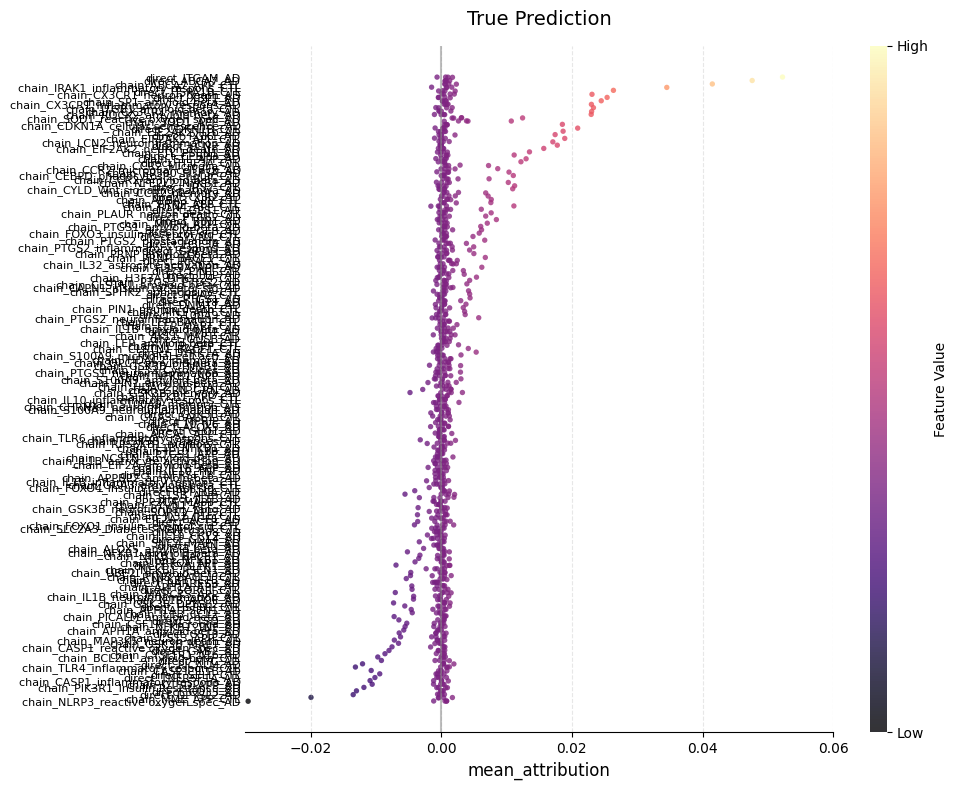

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/3855376912.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_correct_means = df_correct.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/3855376912.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_wrong_means = df_wrong.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_APP_AD', 'chain_HDAC2_H3F3A_CTL', 'chain_CASP1_IL1B_AD', 'chain_HDAC2_memory_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_False Prediction.png


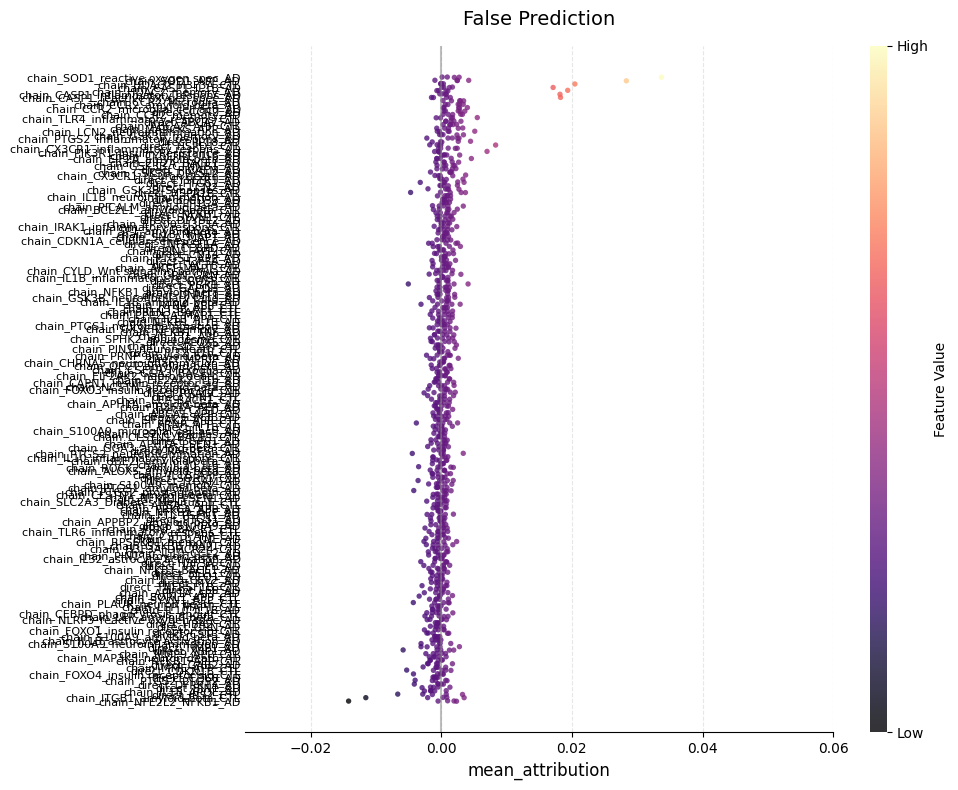

In [43]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"
rule_value_name = 'mean_attribution'

df_direct_t = plot_wrong_correct_mean_rulescore(df_samples=df_attributions, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name=rule_value_name,
                                        plot_correct=True,
                                        cmap='magma',
                                        xlim=(-0.03,0.06),
                                        x_interval=0.02,
                                        save_dir='../nesy_gnn/results/explain/AD_KG/rules'
                                        )

df_direct_f = plot_wrong_correct_mean_rulescore(df_samples=df_attributions, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name=rule_value_name,
                                        plot_correct=False,
                                        cmap='magma',
                                        xlim=(-0.03,0.06),
                                        x_interval=0.02,
                                        save_dir='../nesy_gnn/results/explain/AD_KG/rules'
                                        )

In [ ]:
# df_direct_t = df_direct_t.reset_index()
# df_direct_t = df_direct_t.merge(df_rules, on='rule_name', how='left')

# df_direct_f = df_direct_f.reset_index()
# df_direct_f = df_direct_f.merge(df_rules, on='rule_name', how='left')

for i, row in df_direct_t.iterrows():
    print(row['evidence'])
    if i >=10:
        print()
        break

for i, row in df_direct_f.iterrows():
    print(row['evidence'])
    if i >=10:
        break

p(HGNC:"ITGAM") --positive_correlation--> path(MESH:"Alzheimer Disease")
g(HGNC:"ABCA7") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"ABCA7") → APP → Alzheimer Disease (net sign: -)
r(HGNC:"IRAK1") → inflammatory response → Alzheimer Disease (net sign: -)
p(RGD:"Hspa1b") --negative_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"CX3CR1") → neuron death → Alzheimer Disease (net sign: +)
p(HGNC:"XBP1",var("C, 116, G")) --positive_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"SP1") → amyloid-beta → Alzheimer Disease (net sign: +)
p(HGNC:"CX3CR1") → inflammatory response → Alzheimer Disease (net sign: +)
p(HGNC:"ITGB1") → amyloid-beta → Alzheimer Disease (net sign: -)
p(HGNC:"CX3CR1") → memory → Alzheimer Disease (net sign: +)

p(MGI:"Sod1",var("G, 93, A")) → reactive oxygen species → Alzheimer Disease (net sign: +)
p(HGNC:"SOD1") → APP → Alzheimer Disease (net sign: +)
p(HGNC:"HDAC2") → H3F3A → Alzheimer Disease (net sign: -)
p(HGNC:"CASP1") → IL1B → 

**Why True Predictions resemble TP rules**
+ Disease-Dominant Learning: The model actively relies on disease markers to get things right. It likely treats the "Control" class as a passive default—meaning if it doesn't definitively see the disease, it guesses control. Because the model's active logic is mostly hunting for the disease, the rules driving overall success are almost entirely the TP rules.
  
+ Class Imbalance: If your dataset contains significantly more disease cases than control cases, the TP group mathematically dominates the overall "True predictions" bucket, making their overall rank distributions nearly identical.
  
**Why False Predictions resemble TN rules**
+ "Control" Logic is the Root of Errors: When the model fails, the logic it relies on looks just like the logic it uses to identify healthy patients. This means your TN rules are too aggressive, too broad, or are capturing noisy baseline biological data that also appears in diseased patients.
The Hijacking Effect: This perfectly explains your previous observation where the Wrong Control (FN) group still had disease rules ranked 1-20. The model accurately spots the core disease features, but your overly broad "Control" (TN) rules trigger simultaneously, overpower the correct disease rules, and drag the prediction into an error.

+ The model doesn't have a clean, isolated understanding of both classes. It knows what the disease looks like, but its definition of "control" is so loose that it spills over and creates the bulk of your False Positives and False Negatives. To fix this, the model needs to be forced to learn specific, restrictive features that positively identify a control patient, rather than relying on broad rules that hijack otherwise accurate disease predictions.

## Plot TP, TN, FP, FN

In [40]:
def plot_tp_fn_rule_score(df_samples, 
                              df_rules, 
                              dataset, 
                              k, 
                              model_type, 
                              rule_value_name, 
                              cmap="viridis",
                              plot_correct=True, 
                              plot_disease=True,
                              save_dir=None,
                              xlim=None,
                              x_interval=None,
                              ):
    # calculate mean attribution for wrongly & correctly predicted groups samples
    if plot_correct:
        df = df_samples[df_samples['Label']==df_samples['Prediction']]
        tf = 'True'
    else:
        df = df_samples[df_samples['Label']!=df_samples['Prediction']]
        tf = "False"


    df1 = df[df['Prediction']==1]
    df0 = df[df['Prediction']==0]

    # Define the columns to group by
    group_cols = ['dataset', 'k', 'model', 'fold']

    # Identify the rule columns (everything from 'degrees' to the end)
    start_idx = df.columns.get_loc('degrees')
    rule_cols = df.columns[start_idx:].tolist()

    # Calculate the mean for the disease group
    df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
    # Calculate the mean for the control group
    df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()

    # Convert from wide to long format
    if plot_disease:
        df_long = df1_means.melt(
            id_vars=['dataset', 'k', 'model', 'fold'], # Columns to keep as identifiers
            value_vars=rule_cols,                      # The rule columns to unpivot
            var_name='rule_name',                      # New column containing the rule names
            value_name=rule_value_name,        # New column containing the values
        )
        tf += " Positive"
        title = f"{tf} Prediction"
    else:
        df_long = df0_means.melt(
            id_vars=['dataset', 'k', 'model', 'fold'], # Columns to keep as identifiers
            value_vars=rule_cols,                      # The rule columns to unpivot
            var_name='rule_name',                      # New column containing the rule names
            value_name=rule_value_name,        # New column containing the values
        )
        tf += " Negative"
        title=f"{tf} Prediction"

    plot_df = df_long[
        (df_long['dataset']==dataset) &
        (df_long['k']==k) &
        (df_long['model']==model_type)
    ].copy()

    plot_df = plot_df.dropna(axis=0)
    x_col=rule_value_name
    y_col='rule_name'

    # Sort rules by their mean importance so the most important is at the top
    # Double brackets [[x_col]] and by=x_col safely prevents DataFrame sorting errors
    mean_importance = plot_df.groupby(y_col)[[x_col]].mean()
    order = mean_importance.sort_values(by=x_col, ascending=False).index
    df_ordered_rule = mean_importance.sort_values(by=x_col, ascending=False)

    df_rules = df_rules.rename(columns={'name':'rule_name'})

    df_ordered_rule = df_ordered_rule.reset_index()
    df_correct_disease = df_ordered_rule.merge(df_rules, on='rule_name', how='left')

    # save rule order and plot
    save_path = None
    save_rule = None
    if save_dir is not None:
        save_path = os.path.join(save_dir, f"{dataset}_{model_type}_{title}.png")
        save_rule = os.path.join(save_dir, f"Ordered_rules_{dataset}_{model_type}_{title}.csv")
        

    df_orded_rules = plot_rule_importance(df=plot_df,
                            x_col=x_col,
                            y_col=y_col,
                            title=title,
                            interpolate=False,
                            cmap=cmap,
                            save_path = save_path,
                            xlim=xlim,
                            x_interval=x_interval)

    df_correct_disease.to_csv(save_rule)

    return df_correct_disease

### Direct Rules

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['direct_ITGAM_AD', 'direct_ABCA7_AD', 'chain_ABCA7_APP_CTL', 'chain_IRAK1_inflammatory respons_CTL', 'direct_HSPA1B_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_True Positive Prediction.png


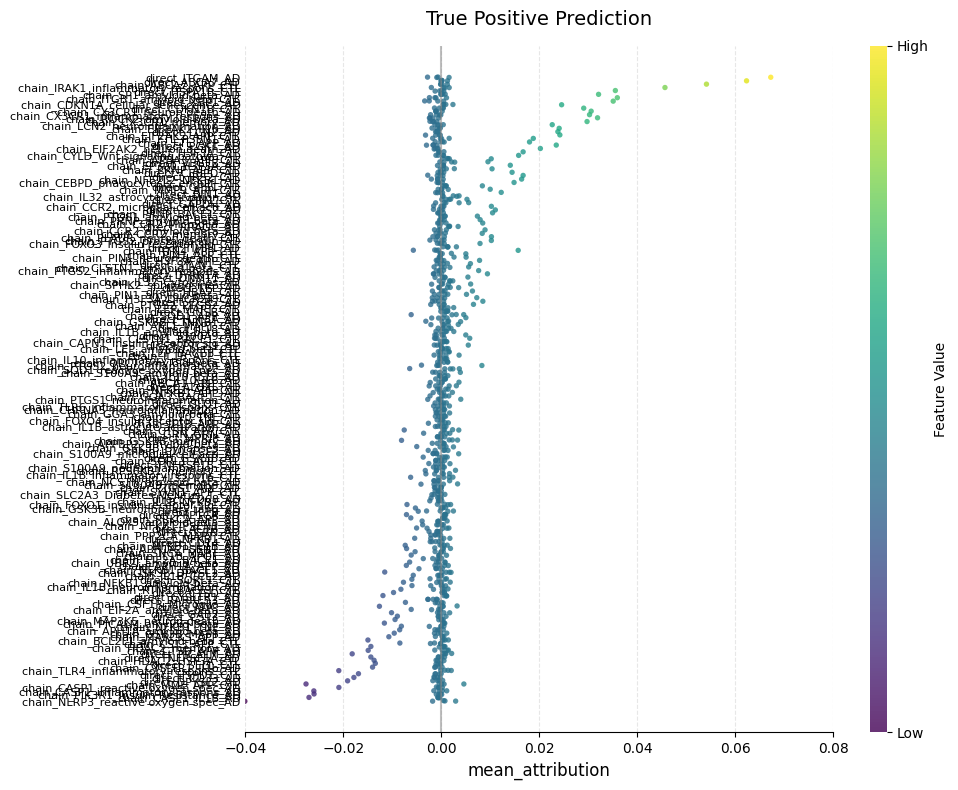

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_APP_AD', 'chain_HDAC2_H3F3A_CTL', 'chain_HDAC2_memory_AD', 'chain_CASP1_IL1B_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_True Negative Prediction.png


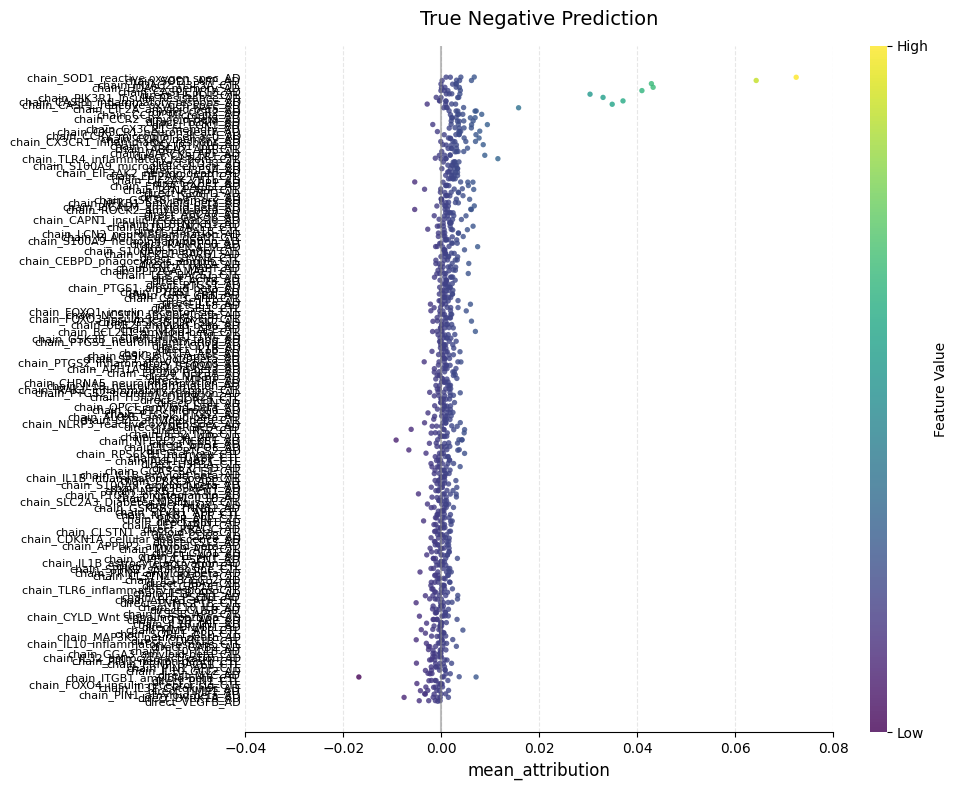

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_APP_AD', 'chain_CASP1_inflammatory respons_AD', 'chain_CASP1_IL1B_AD', 'chain_HDAC2_memory_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_False Positive Prediction.png


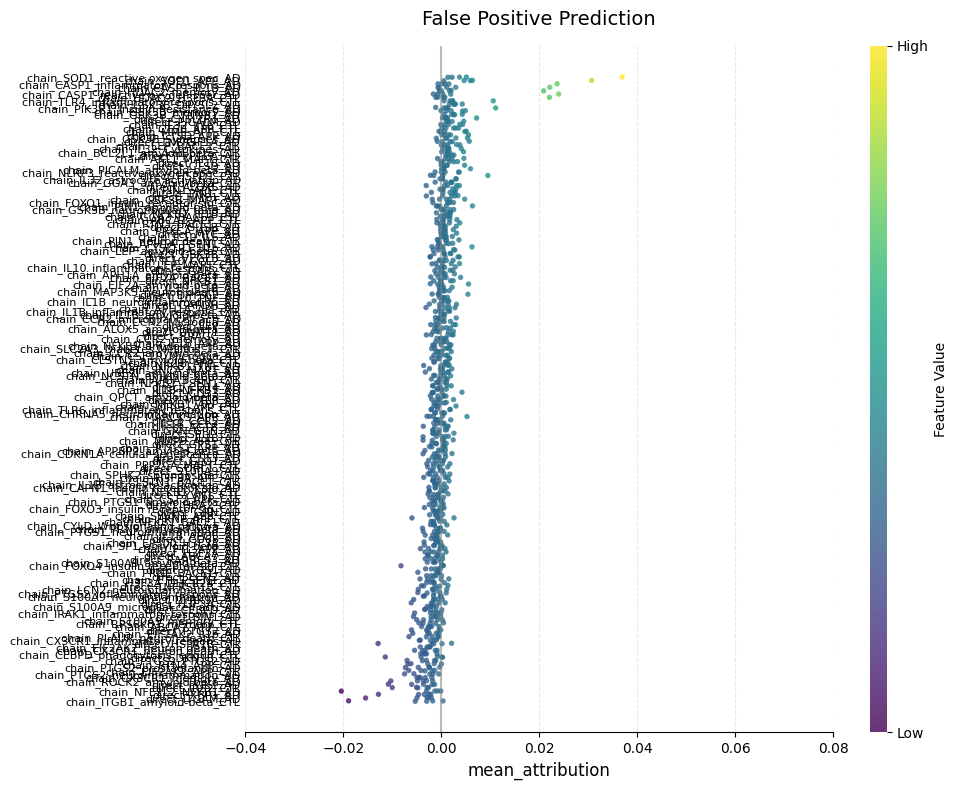

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['direct_ITGAM_AD', 'chain_ABCA7_APP_CTL', 'direct_PGK1_AD', 'chain_ROCK2_amyloid-beta_AD', 'direct_HSPA1B_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_False Negative Prediction.png


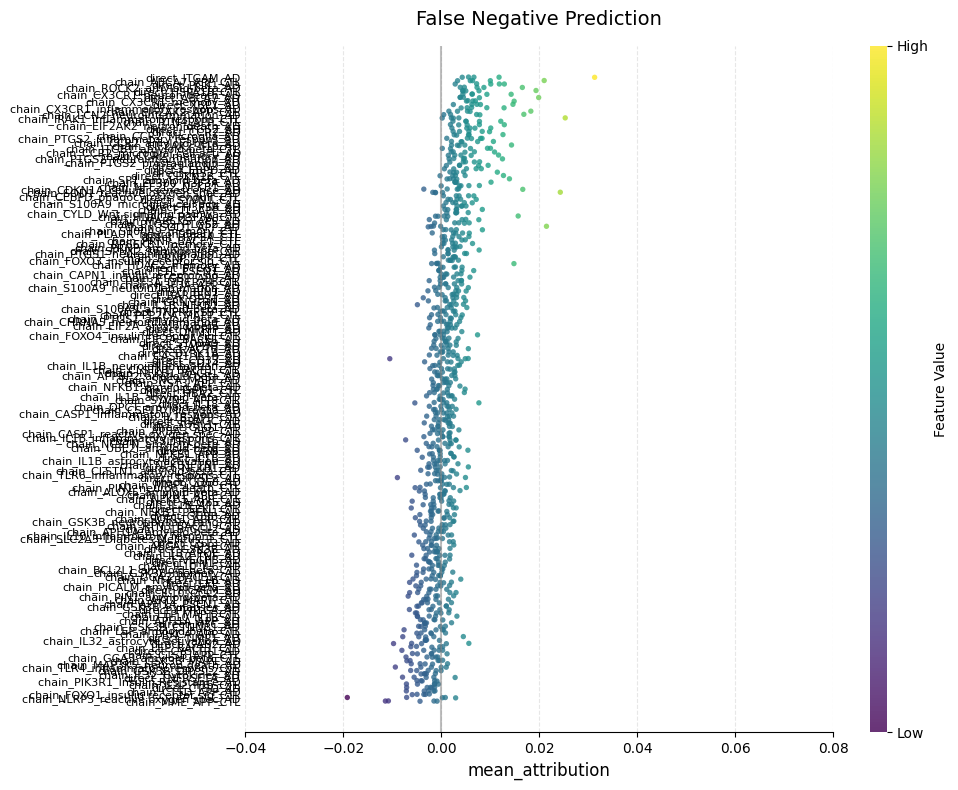

In [41]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"
rule_value_name = 'mean_attribution'
save_dir = '../nesy_gnn/results/explain/AD_KG/rules'

df_dtp = plot_tp_fn_rule_score(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=True,
                                               xlim=(-0.04,0.08),
                                               x_interval=0.02,
                                               save_dir=save_dir)
df_dtn = plot_tp_fn_rule_score(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=False,
                                               xlim=(-0.04,0.08),
                                               x_interval=0.02,
                                               save_dir=save_dir)
df_dfp = plot_tp_fn_rule_score(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=True,
                                               xlim=(-0.04,0.08),
                                                x_interval=0.02,
                                                save_dir=save_dir)
df_dfn = plot_tp_fn_rule_score(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=False,
                                               xlim=(-0.04,0.08),
                                                x_interval=0.02,
                                                save_dir=save_dir)

In [35]:
df_dtp.tail(10)

,rule_name,mean_attribution,type,conclusion,n_genes,genes,bp,confidence,evidence
175,chain_TLR4_inflammatory respons_CTL,-0.003394,direct_gene_ad,CTL,1,TLR4,NaN,0.8,"p(HGNC:""TLR4"") → inflammatory response → Alzhe..."
176,direct_HSPD1_CTL,-0.003950,direct_gene_ad,CTL,1,HSPD1,NaN,1.0,"p(RGD:""Hspd1"") --negative_correlation--> path(..."
177,direct_CD33_AD,-0.004358,direct_gene_ad,AD,1,CD33,NaN,1.0,"g(HGNC:""CD33"") --rev_increases--> path(MESH:""A..."
178,direct_DPYSL2_AD,-0.004385,direct_gene_ad,AD,1,DPYSL2,NaN,1.0,"p(HGNC:""DPYSL2"",pmod(Ph)) --positive_correlati..."
179,chain_MME_APP_CTL,-0.004569,direct_gene_ad,CTL,1,MME,NaN,0.8,"p(HGNC:""MME"") → APP → Alzheimer Disease (net s..."
180,chain_CASP1_reactive oxygen spec_AD,-0.004570,direct_gene_ad,AD,1,CASP1,NaN,0.8,"p(HGNC:""CASP1"") → reactive oxygen species → Al..."
181,chain_CASP1_inflammatory respons_AD,-0.005333,direct_gene_ad,AD,1,CASP1,NaN,0.8,"p(HGNC:""CASP1"") → inflammatory response → Alzh..."
182,chain_PIK3R1_Insulin Resistance_AD,-0.005525,direct_gene_ad,AD,1,PIK3R1,NaN,0.8,"p(HGNC:""PIK3R1"",var(""M,326,I"")) → Insulin Resi..."
183,chain_CASP1_IL1B_AD,-0.005863,direct_gene_ad,AD,1,CASP1,NaN,0.8,"p(HGNC:""CASP1"") → IL1B → Alzheimer Disease (ne..."
184,chain_NLRP3_reactive oxygen spec_AD,-0.007563,direct_gene_ad,AD,1,NLRP3,NaN,0.8,"p(HGNC:""NLRP3"") → reactive oxygen species → Al..."


In [34]:
dfs = [df_dtp, df_dtn, df_dfp, df_dfn]
names = ['TP', 'TN', 'FP', 'FN']

for (df, name) in zip(dfs, names):
    print(name)
    for i, row in df.iterrows():
        print(row['evidence'])
        if i >9:
            print()
            break

TP
p(HGNC:"ITGAM") --positive_correlation--> path(MESH:"Alzheimer Disease")
g(HGNC:"ABCA7") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"ABCA7") → APP → Alzheimer Disease (net sign: -)
r(HGNC:"IRAK1") → inflammatory response → Alzheimer Disease (net sign: -)
p(RGD:"Hspa1b") --negative_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"SP1") → amyloid-beta → Alzheimer Disease (net sign: +)
p(HGNC:"ITGB1") → amyloid-beta → Alzheimer Disease (net sign: -)
p(HGNC:"XBP1",var("C, 116, G")) --positive_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"CDKN1A") → cellular senescence → Alzheimer Disease (net sign: +)
p(HGNC:"CDKN1B") --negative_correlation--> path(MESH:"Alzheimer Disease")
p(HGNC:"CX3CR1") → neuron death → Alzheimer Disease (net sign: +)

TN
p(MGI:"Sod1",var("G, 93, A")) → reactive oxygen species → Alzheimer Disease (net sign: +)
p(HGNC:"SOD1") → APP → Alzheimer Disease (net sign: +)
p(HGNC:"HDAC2") → H3F3A → Alzheimer Disease (net sign: -)
p(HGNC:

### All KGRules

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['chain_TXN_5hops_CTL', 'chain_ABCA7_4hops_AD', 'chain_ABCA7_3hops_CTL', 'direct_ABCA7_AD', 'chain_ITGAM_5hops_CTL']


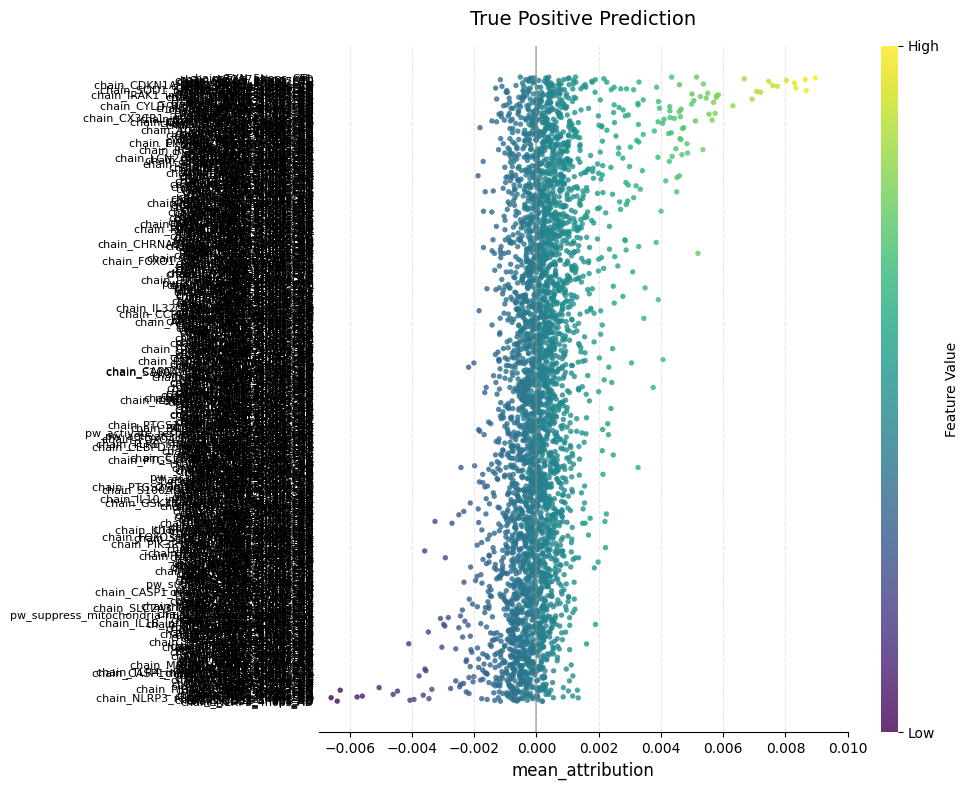

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['chain_TXN_5hops_CTL', 'chain_SOD1_5hops_AD', 'chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_4hops_CTL', 'chain_SOD1_APP_AD']


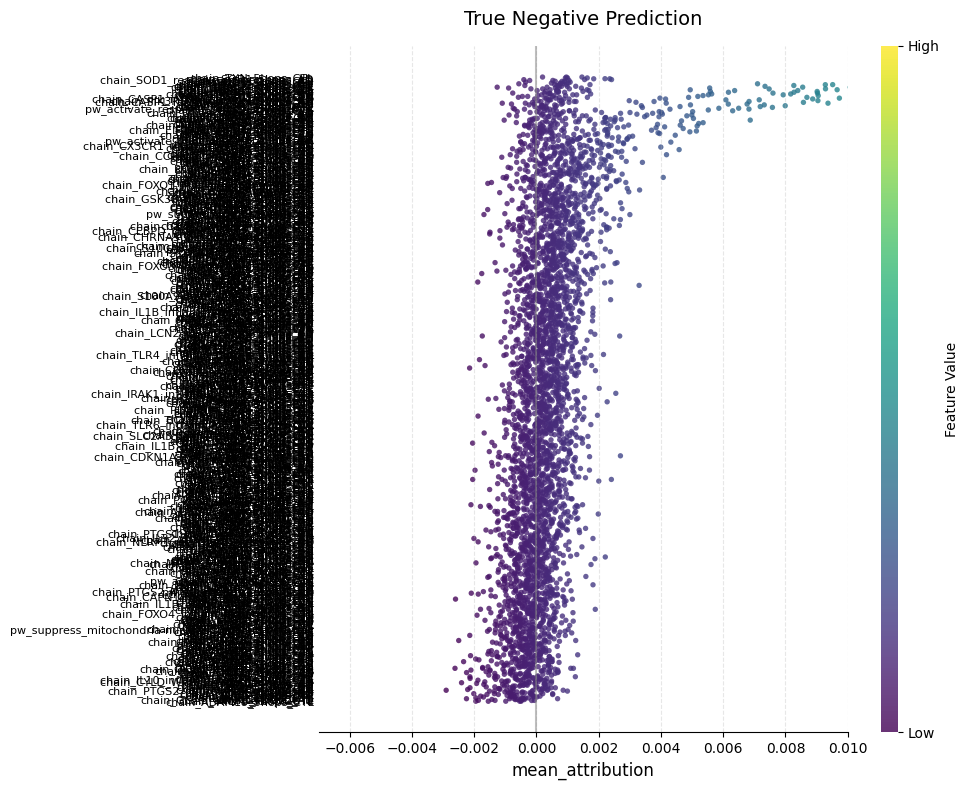

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['chain_TXN_5hops_CTL', 'chain_SOD1_4hops_CTL', 'chain_SOD1_5hops_CTL', 'chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_4hops_AD']


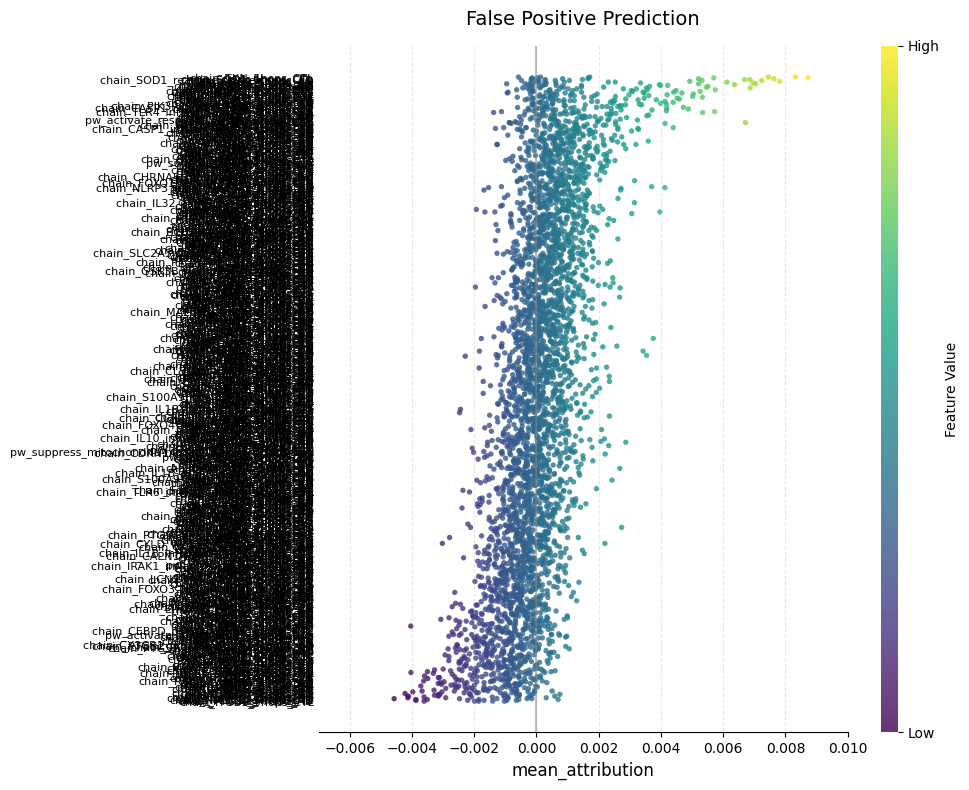

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_87416/4252697778.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_attribution:
['direct_ITGAM_AD', 'chain_ABCA7_3hops_CTL', 'chain_IRAK1_3hops_CTL', 'chain_ABCA7_4hops_CTL', 'chain_ROCK2_3hops_AD']


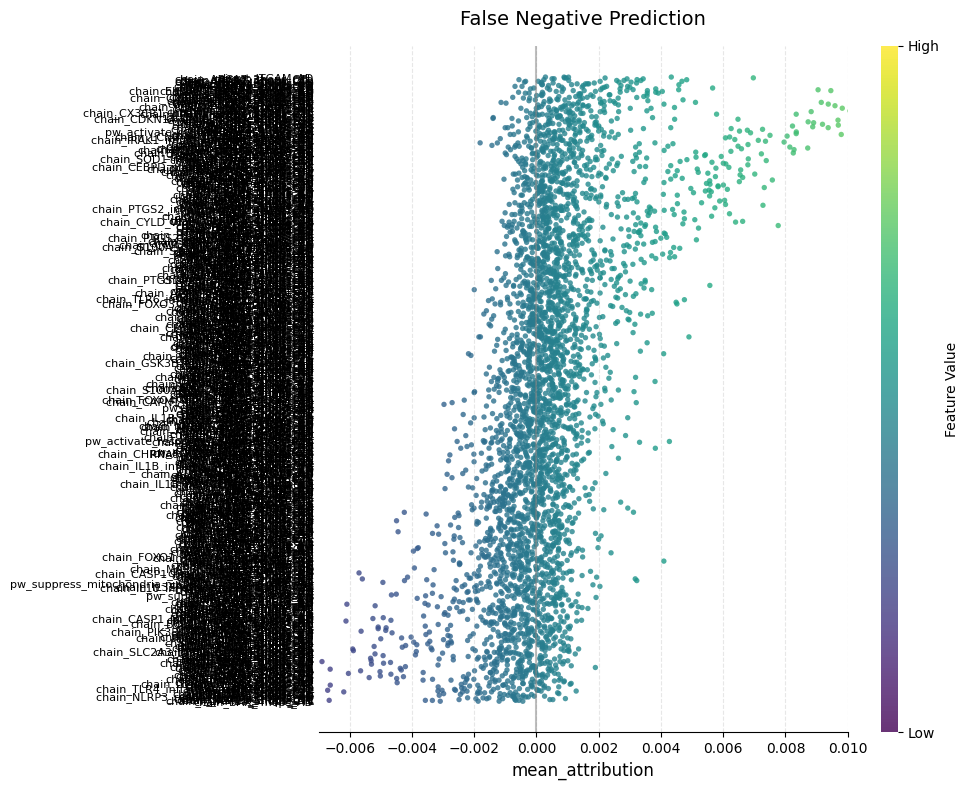

In [12]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_all_rules"
rule_value_name = 'mean_attribution'

df_tp = plot_tp_fn_rule_score(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=True,
                                               xlim=(-0.007,0.01),
                                                x_interval=0.002,)
df_tn = plot_tp_fn_rule_score(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=False,
                                               xlim=(-0.007,0.01),
                                                x_interval=0.002,)
df_fp = plot_tp_fn_rule_score(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=True,
                                               xlim=(-0.007,0.01),
                                                x_interval=0.002,)
df_fn = plot_tp_fn_rule_score(df_samples=df_attributions,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=False,
                                               xlim=(-0.007,0.01),
                                                x_interval=0.002,)

In [32]:
df_tp.tail(10)

,rule_name,mean_attribution,type,conclusion,n_genes,genes,bp,confidence,evidence
731,chain_SELL_5hops_AD,-0.000886,causal_chain,AD,1,SELL,NaN,0.45,SELL → Alzheimer Disease → MMP2 → amyloid-beta...
732,chain_NLRP3_5hops_CTL,-0.001037,causal_chain,CTL,1,NLRP3,NaN,0.45,NLRP3 → reactive oxygen species → APP → nitric...
733,chain_DPYSL2_4hops_AD,-0.001114,causal_chain,AD,1,DPYSL2,NaN,0.60,DPYSL2 → Alzheimer Disease → homocysteine → la...
734,chain_MME_4hops_CTL,-0.001142,causal_chain,CTL,1,MME,NaN,0.60,MME → APP → APP → Alzheimer Disease
735,chain_NLRP3_reactive oxygen spec_AD,-0.001174,direct_gene_ad,AD,1,NLRP3,NaN,0.80,"p(HGNC:""NLRP3"") → reactive oxygen species → Al..."
736,chain_NLRP3_3hops_AD,-0.001287,causal_chain,AD,1,NLRP3,NaN,0.75,NLRP3 → reactive oxygen species → Alzheimer Di...
737,chain_CD33_5hops_AD,-0.001315,causal_chain,AD,1,CD33,NaN,0.45,CD33 → Alzheimer Disease → APOE → amyloid-beta...
738,chain_DPYSL2_5hops_AD,-0.001360,causal_chain,AD,1,DPYSL2,NaN,0.45,DPYSL2 → Alzheimer Disease → APOE → amyloid-be...
739,chain_CD33_4hops_AD,-0.001407,causal_chain,AD,1,CD33,NaN,0.60,CD33 → Alzheimer Disease → homocysteine → late...
740,chain_NLRP3_4hops_AD,-0.001563,causal_chain,AD,1,NLRP3,NaN,0.60,NLRP3 → reactive oxygen species → APP → Alzhei...


In [67]:
dfs = [df_tp, df_tn, df_fp, df_fn]
names = ['TP', 'TN', 'FP', 'FN']

for (df, name) in zip(dfs, names):
    print(name)
    for i, row in df.iterrows():
        print(row['evidence'])
        if i >9:
            print()
            break

TP
TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
ABCA7 → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
ABCA7 → APP → Alzheimer Disease
g(HGNC:"ABCA7") --rev_positive_correlation--> path(MESH:"Alzheimer Disease")
ITGAM → Alzheimer Disease → MMP2 → amyloid-beta → late-onset Alzheimers disease
ABCA7 → Alzheimer Disease → MMP2 → amyloid-beta → late-onset Alzheimers disease
SOD1 → APP → IDE → amyloid-beta → late-onset Alzheimers disease
IRAK1 → inflammatory response → amyloid-beta → Alzheimer Disease
p(HGNC:"CDKN1A") → cellular senescence → Alzheimer Disease (net sign: +)
CDKN1A → cellular senescence → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
ITGAM → Alzheimer Disease → APOE → amyloid-beta → late-onset Alzheimers disease

TN
TXN → MAP3K5 → apoptotic process → neuron death → Alzheimer Disease
Sod1 → reactive oxygen species → Alzheimer Disease → homocysteine → late-onset Alzheimers disease
p(MGI:"Sod1",var("G, 93, A")) → reactiv

## Literature Evidence Combining with Data

In [3]:
exp = pd.read_csv("../data/ANMerge/ANMerge_TX_preprocessed/AnmergeTX_cleaned_exp.csv", index_col=0)
design = pd.read_csv("../data/ANMerge/design_2cls_3cl_target.csv", index_col=0)
design

,Visit,Month,Site,Diagnosis,Sex,Age,APOE,MMSE,Gexp_batch,Diagnosis_clean,Target
Patients,,,,,,,,,,,
DCR00001_1,1.0,0.0,DCR,AD,Female,80.0,E3E4,21.0,2.0,AD,Disease
DCR00004_1,1.0,0.0,DCR,MCI,Male,78.0,E4E4,27.0,2.0,MCI,Disease
DCR00009_1,1.0,0.0,DCR,CTL,Female,69.0,E3E3,30.0,2.0,CN,Control
DCR00013_1,1.0,0.0,DCR,CTL,Male,82.0,E3E3,30.0,2.0,CN,Control
DCR00014_1,1.0,0.0,DCR,CTL,Female,75.0,E2E3,30.0,2.0,CN,Control
...,...,...,...,...,...,...,...,...,...,...,...
TLSMCI607_1,1.0,0.0,Toulouse,MCI,Female,72.0,E3E3,29.0,1.0,MCI,Disease
TLSMCI608_1,1.0,0.0,Toulouse,MCI,Male,73.0,E3E3,28.0,1.0,MCI,Disease
TLSMCI609_1,1.0,0.0,Toulouse,MCI,Female,63.0,E3E3,28.0,2.0,MCI,Disease


In [4]:
exp['label'] = design['Target']
exp

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_47026/3980121252.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  exp['label'] = design['Target']


,AAK1,AARS,AATF,ABCA1,ABCA7,ABCC5,ABCF1,ABHD3,ABHD5,ABI1,...,ZNHIT3,ZNRD1,ZRANB2,ZSCAN18,ZSWIM1,ZSWIM6,ZYG11B,ZYX,ZZEF1,label
Patients,,,,,,,,,,,,,,,,,,,,,
DCR00001_1,7.782714,7.548047,7.393653,7.459898,7.352605,5.902026,6.867753,5.843253,7.787693,7.111270,...,6.604869,6.194367,6.663717,6.056047,6.595746,6.053606,8.554296,9.927704,6.676643,Disease
DCR00004_1,7.205715,7.558911,7.138090,7.054263,6.880459,5.712696,6.910326,6.751203,7.271412,7.687144,...,7.337839,5.932550,7.892525,6.607798,6.393243,6.789879,8.262538,9.887739,6.576720,Disease
DCR00009_1,7.341200,7.818912,7.356901,7.445323,7.115552,5.417825,7.165984,6.709884,8.628254,7.452751,...,6.394684,5.965504,8.458515,6.505912,6.548291,7.072138,8.371842,9.918781,6.895921,Control
DCR00013_1,7.935889,8.074496,7.450045,6.720850,7.169061,5.510676,7.214431,6.454829,7.926513,7.087462,...,6.488639,6.512811,7.005904,6.566939,6.724811,6.517049,8.447815,9.947813,6.887713,Control
DCR00014_1,7.785110,8.119010,7.547462,7.685029,7.541555,5.657996,7.280171,6.144493,7.366412,6.706532,...,6.996030,6.082367,6.512879,7.133244,6.780083,5.897456,8.707624,9.781394,6.971133,Control
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TLSMCI607_1,8.943149,9.852918,9.616939,8.027275,7.670197,7.278570,9.251805,7.495878,6.744970,7.334809,...,9.173281,8.203224,8.745452,9.017837,7.827721,7.368520,10.228047,10.786171,7.870283,Disease
TLSMCI608_1,8.186177,8.790977,9.672985,8.917365,8.600835,7.867951,8.345912,8.599297,8.549334,7.800063,...,7.847145,7.684884,7.160109,7.726906,8.071681,7.819223,10.769907,12.067203,8.299378,Disease
TLSMCI609_1,7.634274,8.089203,6.898251,8.407507,6.485419,5.686370,7.045064,7.149941,7.572056,7.937760,...,7.473756,6.023116,8.390669,7.124253,6.388340,6.551000,7.993508,9.581571,7.024413,Disease


In [5]:
exp_1 = exp[exp['label']=='Disease']
exp_0 = exp[exp['label']=='Control']
mean_exp_1 = exp_1.drop(columns='label').mean(axis=0).to_dict()
mean_exp_0 = exp_0.drop(columns='label').mean(axis=0).to_dict()
mean_exp_1

{'AAK1': 8.003582064837104,
 'AARS': 8.599027311067873,
 'AATF': 8.363655154615385,
 'ABCA1': 8.171792604506788,
 'ABCA7': 7.755230619669683,
 'ABCC5': 6.705274050133485,
 'ABCF1': 8.036841135409503,
 'ABHD3': 7.2663726691651584,
 'ABHD5': 7.876385805350679,
 'ABI1': 7.5651849584819,
 'ABI3': 7.729835964307692,
 'ABLIM1': 9.283694448828056,
 'ABR': 9.320575339255656,
 'ABTB1': 10.27235084088009,
 'ACAA1': 8.228288101780542,
 'ACAD8': 7.043252013484163,
 'ACADM': 6.590199801871041,
 'ACADVL': 8.927080294402716,
 'ACAP1': 8.918065695312217,
 'ACAT2': 6.6878705113506784,
 'ACIN1': 8.472682985852941,
 'ACLY': 8.03281567408484,
 'ACOT9': 6.845437588678733,
 'ACOX1': 7.4806542364728505,
 'ACP1': 8.10048821228733,
 'ACRBP': 7.97384961088009,
 'ACSL1': 9.119048533552036,
 'ACSL4': 7.364679796748869,
 'ACSL5': 8.273978513052038,
 'ACSS2': 8.801859467987557,
 'ACTB': 13.706161381696836,
 'ACTG1': 12.730594905373305,
 'ACTL6A': 7.442161585638009,
 'ACTN1': 10.930887298690045,
 'ACTN4': 8.34590991

In [6]:
prs = ['MAP3K5','ITGAM','ABCA7','IRAK1','HSPA1B','SP1','XBP1','CDKN1A','CDKN1B']

for pr in prs:
    print('-'*10)
    print(f"{pr} mean expression in Disease Group")
    print(mean_exp_1[pr],'\n')

    print(f"{pr} mean expression in Control Group")
    print(mean_exp_0[pr])

----------
MAP3K5 mean expression in Disease Group
9.064871216377828 

MAP3K5 mean expression in Control Group
8.970588492799196
----------
ITGAM mean expression in Disease Group
9.630321543246607 

ITGAM mean expression in Control Group
9.330192552859438
----------
ABCA7 mean expression in Disease Group
7.755230619669683 

ABCA7 mean expression in Control Group
7.450868882429719
----------
IRAK1 mean expression in Disease Group
8.547482485624435 

IRAK1 mean expression in Control Group
8.389396177638556
----------
HSPA1B mean expression in Disease Group
8.227333375678734 

HSPA1B mean expression in Control Group
7.9680946016144585
----------
SP1 mean expression in Disease Group
8.425123823719456 

SP1 mean expression in Control Group
8.237735096755019
----------
XBP1 mean expression in Disease Group
10.097592292467194 

XBP1 mean expression in Control Group
9.975976980949799
----------
CDKN1A mean expression in Disease Group
8.635231401588236 

CDKN1A mean expression in Control Group
